# Predicción del Sector Económico: Comparación de Modelos de Clasificación (ENOE)

**Autor:** Arturo Vargas Espinosa

**Tablero interactivo:** https://foamyhomie327.github.io/Inteligencia-Artificial/sector-economico-comparacion-modelos/app/

# Introducción, Planteamiento del Problema y Contexto

En este proyecto se construyen y comparan distintos modelos de clasificación para predecir el **sector de actividad económica** (primario, secundario o terciario) en el que trabaja una persona trabajando en Mexico, usando los datos de la Encuesta Nacional de Ocupación y Empleo (ENOE) del primer trimestre de 2026 del INEGI. Para predecirlo solo se usan características de la persona y de su empleo: su edad, sus años de escolaridad, las horas que trabaja a la semana, su ingreso mensual, su sexo y si vive en una localidad rural o urbana.

Los tres sectores que se quieren predecir son (variable `rama_est1` de la ENOE):

- **Sector primario:** actividades que obtienen recursos directamente de la naturaleza, como la agricultura, la ganadería, el aprovechamiento forestal, la pesca y la caza. Es el trabajo "del campo" y se concentra sobre todo en zonas rurales.
- **Sector secundario:** actividades que transforman materias primas en productos, como la industria manufacturera (fábricas), la construcción, la minería (industria extractiva) y la generación de electricidad, gas y agua. Es el trabajo "de la industria".
- **Sector terciario:** actividades que no producen bienes sino que ofrecen servicios, como el comercio, el transporte, la educación, la salud, los restaurantes, los servicios financieros y el gobierno. Es el sector que más gente emplea en México (cerca de dos terceras partes de las personas ocupadas).

## ¿Por qué es relevante el problema?

Saber qué perfil de persona trabaja en cada sector ayuda a entender la estructura del mercado laboral en México: por ejemplo, qué tan ligado está el trabajo en el campo a vivir en zonas rurales, o qué tanto se parecen (en ingreso y nivel de estudio) los trabajadores de la industria y de los servicios. Un modelo que logre distinguir bien los 3 sectores con pocas variables sociodemográficas nos dice que esas variables realmente capturan diferencias estructurales entre los sectores.

Esto tiene un beneficio social directo, porque el sector en el que trabaja una persona está muy ligado a sus condiciones de vida:

- El **sector primario** concentra a la población rural, con menos años de escuela y con los ingresos más bajos. Es la población a la que van dirigidos muchos programas de apoyo al campo y de combate a la pobreza rural.
- Si con solo saber dónde vive alguien, cuánto estudió y cuánto gana se puede adivinar en qué sector trabaja, eso quiere decir que **las oportunidades de trabajo no están repartidas igual**: el lugar donde naces y la escuela a la que tienes acceso "deciden" en buena parte el tipo de trabajo que vas a tener. Medir qué tan fuerte es esa relación ayuda a dimensionar esa desigualdad.

La pregunta que se quiere contestar en este proyecto es: **¿qué tan bien se puede predecir el sector económico de una persona con su perfil sociodemográfico, y qué modelo de clasificación lo hace mejor considerando no solo sus métricas, sino también su estabilidad, su interpretabilidad y su costo?** Además, se quiere aprender **qué características separan a cada sector** y en dónde está el límite de lo que se puede predecir con esta información.

## ¿Por qué un enfoque de clasificación?

La variable que se quiere predecir es **cualitativa**: cada persona pertenece a uno de 3 sectores, y los códigos 1, 2 y 3 son solo etiquetas, no cantidades (el sector terciario no "vale" el triple que el primario, ni hay un orden natural entre ellos). Por eso un modelo de regresión no tiene sentido aquí, y lo adecuado es un modelo de **clasificación multiclase**, que estima la probabilidad de que una persona pertenezca a cada sector y le asigna el más probable. Además, varios de estos modelos permiten ver qué variables pesan más en esa decisión, que es justo lo que se quiere entender del fenómeno.

## Fuente y contexto de los datos

La ENOE es la encuesta oficial con la que el INEGI mide cada trimestre el empleo, el desempleo y las condiciones laborales en México. Se levanta en viviendas de todo el país, y a cada integrante del hogar de 12 años o más se le pregunta si trabaja, en qué, cuántas horas, cuánto gana y con qué prestaciones, además de sus características sociodemográficas. Es la fuente con la que se calculan las cifras oficiales de ocupación e informalidad, así que es una base real y confiable para estudiar el mercado laboral mexicano.

Para este análisis se usa el archivo **enoe_2026_1t_limpio.csv**, el mismo que se usó en los proyectos de [regresión del ingreso laboral](../regresion-caso-real-enoe/README.md), [clasificación de prestaciones laborales](../clasificacion-prestaciones-enoe/README.md), [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md) y [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md). El archivo `enoe_2026_1t_limpio.csv` no es un dataset descargado directamente, sino el resultado de un proceso propio de integración. La ENOE distribuye la información en tablas separadas por cuestionario, y cada una por sí sola es insuficiente: `SDEM` (módulo sociodemográfico) trae las variables de la persona y del hogar, pero no el detalle de ocupación y empleo, mientras que `COE2` (segunda parte del cuestionario de ocupación y empleo) trae ese detalle pero no el resto del perfil sociodemográfico. Ninguna de las dos por separado permite construir el modelo, así que se combinan mediante la llave primaria de ocho campos que identifica de forma única a cada entrevistado (entidad, control, UPM, vivienda, selección, hogar, mudanza y renglón).

Antes de ese cruce, `SDEM` por sí sola trae **más de 400,000 registros**, pero la mayoría no sirve para este análisis: incluye entrevistas incompletas o no logradas, visitantes y trabajadores domésticos que no son residentes habituales del hogar, y personas fuera del rango de edad que cubre la encuesta (menores de 12 años, por ejemplo). Se aplican entonces tres filtros de calidad sobre `SDEM`: `r_def == 0` para quedarse solo con entrevistas completas, `c_res` en {1, 3} para conservar a los residentes habituales, y `eda` entre 12 y 98 años para respetar la población objetivo. El cruce con `COE2` se hace con un `inner join`, de modo que solo sobreviven los registros que existen en ambas tablas, y al final se descartan las observaciones sin `ingocup` positivo. Después de estos filtros y del cruce, la base se reduce de los más de 400,000 registros iniciales a las **126,226 observaciones** con las que arranca este reporte. Es decir, la población de estudio son **personas ocupadas en México que reportan un ingreso por su trabajo**.

# Metodología

## Protocolo experimental

Para que la comparación entre modelos sea justa y para que el resultado final sea una estimación honesta de cómo se va a comportar el modelo con datos nuevos, se sigue este protocolo:

1. Se separa la base en **80% entrenamiento y 20% prueba**, de forma estratificada por sector. El set de prueba se aparta desde el inicio y **no se usa para ninguna decisión**: ni para explorar relaciones entre variables, ni para elegir hiperparámetros, ni para elegir el modelo.
2. Los hiperparámetros de cada modelo se eligen usando **solo el set de entrenamiento** (error *out-of-bag*, validación cruzada o una parte del entrenamiento apartada como validación).
3. Todos los modelos se comparan con **validación cruzada estratificada de 5 folds sobre el set de entrenamiento completo**, usando exactamente los mismos 5 folds para todos. Así cada modelo se evalúa 5 veces con datos que no vio al entrenar, y se puede ver no solo qué tan bien le va en promedio, sino qué tanto varía (estabilidad).
4. Con esa evidencia se elige **un solo modelo final**, se reentrena con todo el set de entrenamiento y se evalúa **una sola vez** en el set de prueba.

La razón de hacerlo así es que si se comparan muchos modelos en el set de prueba y se elige el que mejor le fue, el set de prueba deja de ser "independiente": se elegiría en parte el modelo que tuvo suerte con esas 24 mil personas, y su métrica en prueba sería optimista (lo que se conoce como *test set leakage*). Con este protocolo, el número que se reporta al final es el de un modelo que nunca "vio" el set de prueba.

### Regresión logística multinomial

En un problema de clasificación una recta de regresión lineal no es adecuada, porque puede predecir valores fuera del rango [0, 1], que no se pueden interpretar como probabilidad. La **regresión logística** resuelve esto modelando la probabilidad de pertenecer a cada clase. Con más de dos clases se usa la versión **multinomial**, que calcula un puntaje lineal para cada clase $k$ y lo convierte en probabilidad con la función *softmax*:

$$P(Y=k \mid X) = \frac{e^{\beta_{0k} + \beta_{1k}X_1 + \dots + \beta_{pk}X_p}}{\sum_{j=1}^{K} e^{\beta_{0j} + \beta_{1j}X_1 + \dots + \beta_{pj}X_p}}$$

(Ecuaciones hechas con Claude)

Las fronteras entre clases que genera este modelo son **lineales**, así que sirve como punto de comparación de un modelo sencillo.

### Linear Discriminant Analysis (LDA)

LDA parte del teorema de Bayes: para clasificar una observación se calcula, para cada clase $k$, la probabilidad posterior $P(Y=k \mid X=x)$, y se le asigna la clase con mayor probabilidad. Para poder calcular esa probabilidad posterior, LDA asume que las variables explicativas, dentro de cada clase, siguen una **distribución normal multivariada**, y que **todas las clases comparten la misma matriz de covarianza** (homocedasticidad). Bajo esos dos supuestos, la frontera de decisión que resulta de comparar las probabilidades posteriores entre clases es **lineal** en las variables explicativas.

Un supuesto adicional, implícito en cómo LDA usa el teorema de Bayes, es que la **probabilidad a priori** de cada clase (qué tan común es en la población) influye directamente en la clasificación final. Si las clases están desbalanceadas, como es el caso aquí, un modelo con las probabilidades a priori por default (las proporciones observadas en los datos) tenderá a favorecer a la clase mayoritaria; por eso aquí se usan probabilidades a priori iguales para las 3 clases.

### Árboles de decisión

Un árbol de decisión, en cambio, no asume nada sobre la distribución de las variables ni sobre la forma de la frontera: construye la clasificación **estratificando el espacio de las variables explicativas en regiones**, usando una serie de reglas de separación binarias (¿la variable X es mayor o menor que cierto valor?), y predice la clase más común (la moda) dentro de cada región resultante. Cada separación se elige para maximizar la **pureza** de los nodos resultantes (minimizar el índice de Gini, en el caso de `DecisionTreeClassifier` de sklearn).

Un árbol sin restricciones tiende a crecer hasta que cada hoja es perfectamente pura, lo cual genera **sobreajuste** severo. Para evitar esto se usa **cost-complexity pruning (poda por complejidad de costo)**: se penaliza la función de costo del árbol por cada hoja adicional que tenga, usando un parámetro $\alpha$ que controla qué tan agresiva es la poda. El valor óptimo de $\alpha$ se selecciona mediante **validación cruzada**.

### Random Forest

Un árbol de decisión es muy interpretable pero es **volátil**: si cambiamos un poco los datos de entrenamiento, el árbol resultante puede cambiar mucho (tiene alta varianza). La idea de los métodos de ensamble es combinar muchos modelos para reducir esa varianza.

- **Bagging (bootstrap aggregation):** se generan muchas muestras *bootstrap* (muestras del mismo tamaño que el set de entrenamiento, pero tomadas **con reemplazo**), se entrena un árbol profundo en cada una, y la predicción final es la clase que más árboles votaron (mayoría).
- **Random Forest** agrega un truco extra: en cada separación de cada árbol solo se permite elegir entre un subconjunto aleatorio de $m$ variables (típicamente $m \approx \sqrt{p}$). Esto sirve porque si hay una variable muy fuerte (como `ur01`), en bagging casi todos los árboles la usarían en el primer nodo y serían muy parecidos entre sí (predicciones correlacionadas); al obligar a los árboles a usar otras variables, se "descorrelacionan" y el promedio reduce más la varianza.
- **Error out-of-bag (OOB):** en promedio cada muestra bootstrap contiene aproximadamente dos terceras partes de las observaciones; el tercio restante (las observaciones *out-of-bag*) se puede usar para evaluar el modelo sin necesidad de un set de validación aparte. Aquí se usa el OOB para elegir el tamaño mínimo de hoja.

### Boosting

En boosting los árboles **no** se entrenan de forma independiente, sino **secuencial**: cada árbol nuevo se enfoca en corregir los errores de los árboles anteriores. Se usan árboles pequeños ("weak learners"), y cada uno aporta solo un poquito (controlado por el *learning rate*), así que el modelo aprende lentamente.

- En **AdaBoost** esto se logra dándole más peso a las observaciones mal clasificadas en la siguiente iteración.
- En **Gradient Boosting** (el que se usa aquí) cada árbol nuevo se ajusta al gradiente de la función de pérdida (los "residuales") del modelo acumulado hasta ese momento.

A diferencia de Random Forest, en boosting agregar demasiados árboles **sí** puede generar sobreajuste, por eso se usa *early stopping*: se aparta una parte del entrenamiento como validación y se deja de agregar árboles cuando la pérdida en validación deja de mejorar.

### Support Vector Machine (SVM)

La idea base es el **clasificador de margen máximo**: de todos los hiperplanos que separan a dos clases, se elige el que queda más lejos de las observaciones (el que deja la "franja" más ancha entre las clases). Como en datos reales las clases casi nunca son perfectamente separables, se usa un **margen suave** (*support vector classifier*), que permite que algunas observaciones queden del lado incorrecto del margen o incluso del hiperplano. El parámetro $C$ controla qué tanto se castigan esas violaciones: un $C$ grande castiga mucho los errores (margen más estrecho, más riesgo de sobreajuste) y un $C$ chico los tolera más (margen más ancho, más sesgo).

Cuando la frontera entre clases no es lineal, la **SVM** usa un **kernel**, una función que mide la similitud entre observaciones y equivale a trabajar en un espacio de variables mucho más grande (incluso infinito, en el caso del kernel RBF o radial) sin tener que calcularlo explícitamente. La frontera final solo depende de los **vectores de soporte** (las observaciones que quedan sobre el margen o lo violan). Para más de 2 clases, `SVC` de sklearn usa el esquema *one-vs-one* (un clasificador por cada par de clases, y gana la clase con más votos).

La SVM es sensible a la escala de las variables (usa distancias), así que hay que estandarizar.

### Red neuronal

Una red neuronal *feedforward* está formada por capas de neuronas: una capa de entrada (las variables), una o más capas ocultas y una capa de salida. Cada neurona calcula una **suma ponderada** de sus entradas más un sesgo y le aplica una **función de activación** no lineal (aquí **ReLU** en las capas ocultas). Para clasificación multiclase la capa de salida tiene una neurona por clase con activación **softmax**, que convierte las salidas en probabilidades que suman 1.

Los pesos se aprenden con **gradiente descendente** (en este caso con el optimizador **Adam**), usando **backpropagation** para calcular cuánto contribuyó cada peso al error, y minimizando la pérdida *sparse categorical cross-entropy*. Para evitar sobreajuste se usa **early stopping** monitoreando la pérdida en un conjunto de validación (apartado del entrenamiento).

### Métricas de evaluación

Como las clases están muy desbalanceadas (el sector terciario tiene casi dos terceras partes de las observaciones), la **exactitud** por sí sola es engañosa: un modelo que siempre prediga "terciario" tendría 65.6% de exactitud sin haber aprendido nada. Por eso la métrica principal para comparar es el **F1-score macro** (promedio simple del F1 de las 3 clases, sin ponderar por su tamaño), acompañada de la exactitud, la precisión y la sensibilidad macro, la sensibilidad por clase y la matriz de confusión.

- **Precisión** de una clase: de las personas que el modelo dijo que eran de ese sector, qué porcentaje sí lo era.
- **Sensibilidad (recall)** de una clase: de las personas que sí son de ese sector, qué porcentaje detectó el modelo.
- **F1-score:** la media armónica de las dos anteriores; solo es alto si las dos son altas.

Además, para revisar **sobreajuste** se compara el F1 macro en entrenamiento contra el de validación, y para revisar **estabilidad** se ve la desviación estándar del F1 macro entre los 5 folds.

# Exploración y comprensión del conjunto de datos

Empezamos importando las librerías y leyendo el archivo con `read_csv`. Cada fila es una persona ocupada encuestada.

In [1]:
import os
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
warnings.filterwarnings('ignore')

ruta = 'Datos/enoe_2026_1t_limpio.csv'

df = pd.read_csv(ruta, low_memory=False)
print(df.shape)
df.head()

(126226, 30)


,r_def,cve_ent,con,upm,n_pro_viv,v_sel,n_hog,h_mud,n_ren,c_res,...,tue1,pre_asa,niv_ins,anios_esc,hrsocup,ingocup,imssissste,emp_ppal,p6c,p6d
0,0,9,40006,906681,117,5,1,0,1,1,...,2,1,3,11,50,10000,1,2,,1
1,0,9,40018,912598,63,3,1,0,5,1,...,3,2,4,12,30,12900,4,1,,6
2,0,9,40018,912598,81,4,1,0,3,1,...,2,1,4,15,40,10000,2,2,,3
3,0,9,40039,922769,109,5,1,0,2,1,...,3,0,4,12,40,12900,4,1,,6
4,0,9,40040,911404,7,2,1,0,1,1,...,1,2,2,9,15,9000,4,1,,6


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 126226 entries, 0 to 126225
Data columns (total 30 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   r_def       126226 non-null  int64
 1   cve_ent     126226 non-null  int64
 2   con         126226 non-null  int64
 3   upm         126226 non-null  int64
 4   n_pro_viv   126226 non-null  int64
 5   v_sel       126226 non-null  int64
 6   n_hog       126226 non-null  int64
 7   h_mud       126226 non-null  int64
 8   n_ren       126226 non-null  int64
 9   c_res       126226 non-null  int64
 10  sex         126226 non-null  int64
 11  eda         126226 non-null  int64
 12  n_hij       126226 non-null  str  
 13  e_con       126226 non-null  int64
 14  ur          126226 non-null  int64
 15  zona        126226 non-null  int64
 16  pos_ocu     126226 non-null  int64
 17  seg_soc     126226 non-null  int64
 18  rama_est1   126226 non-null  int64
 19  ambito2     126226 non-null  int64
 20  tue1        126

El archivo tiene **126,226 observaciones y 30 columnas**, exactamente el mismo dataset que se uso en los proyectos anteriores con la ENOE. Casi todas las columnas se leen como `int64`, incluidas varias que en realidad son cualitativas (`sex`, `ur`, `pos_ocu`, `e_con`, `rama_est1`, `ambito2`, `tue1`, `niv_ins`, `imssissste`, entre otras): son categorías codificadas con números, no cantidades. Esto confirma que **el tipo de dato que reporta pandas no es el tipo estadístico de la variable**. De las 30 columnas:

- **10 son identificadores de la encuesta** (`r_def`, `cve_ent`, `con`, `upm`, `n_pro_viv`, `v_sel`, `n_hog`, `h_mud`, `n_ren`, `c_res`): llaves y banderas de control del levantamiento, sin información sobre el fenómeno de interés.
- **2 se leyeron como texto** (`n_hij` y `p6c`), señal de que tienen valores no numéricos escondidos (se revisan más abajo).
- El resto son las variables sociodemográficas y laborales de la persona (sexo, edad, estado civil, escolaridad, horas trabajadas, ingreso, sector, tipo de unidad económica, acceso a seguridad social, formalidad, etc.).

No hay valores nulos en el sentido de pandas (todas las columnas tienen 126,226 valores no nulos), pero eso no quiere decir que no haya datos faltantes: en la ENOE los faltantes vienen como códigos numéricos o como espacios en blanco.

## Diccionario de datos

Como los nombres de las columnas de la ENOE no son autoexplicativos, se incluye el diccionario de las variables del fenómeno (los 10 identificadores no se describen porque se eliminan). La última columna indica qué papel juega cada variable en este proyecto; más adelante, en la sección de preparación, se justifica por qué se dejan fuera las que no se usan.

Tabla 1. Diccionario de datos

| Variable | Tipo | Descripción y códigos | Uso en este proyecto |
|---|---|---|---|
| `rama_est1` | Cualitativa | Sector de actividad: 1 = primario, 2 = secundario, 3 = terciario, 4 = no especificado | **Variable de salida** |
| `eda` | Cuantitativa | Edad en años cumplidos (12 a 98) | Explicativa |
| `anios_esc` | Cuantitativa | Años de escolaridad acumulados (0 a 24; 99 = no especificado) | Explicativa |
| `hrsocup` | Cuantitativa | Horas trabajadas a la semana en la ocupación principal | Explicativa |
| `ingocup` | Cuantitativa | Ingreso mensual por ocupación, en pesos | Explicativa (y su logaritmo `log_ingocup`) |
| `sex` | Cualitativa | Sexo: 1 = hombre, 2 = mujer | Explicativa (recodificada a `sex01`) |
| `ur` | Cualitativa | Ámbito de residencia: 1 = urbano, 2 = rural | Explicativa (recodificada a `ur01`) |
| `n_hij` | Cuantitativa | Número de hijos nacidos vivos (solo se pregunta a mujeres) | No se usa (hueco estructural) |
| `e_con` | Cualitativa | Estado conyugal: 1 = unión libre, 2 = separado, 3 = divorciado, 4 = viudo, 5 = casado, 6 = soltero, 9 = no especificado | No se usa |
| `zona` | Cualitativa | Zona salarial: 1 = Zona Libre de la Frontera Norte, 2 = resto del país | No se usa |
| `pos_ocu` | Cualitativa | Posición en la ocupación: 1 = subordinado remunerado, 2 = empleador, 3 = trabajador por cuenta propia | No se usa |
| `seg_soc` | Cualitativa | Condición de acceso a seguridad social: 1 = con acceso, 2 = sin acceso, 3 = no especificado | No se usa |
| `ambito2` | Cualitativa | Tipo de unidad económica donde labora (incluye una categoría agropecuaria) | No se usa (fuga de datos) |
| `tue1` | Cualitativa | Tipo de unidad económica agrupado: 1 = empresas y negocios, 2 = instituciones, 3 = sector informal y hogares, 4 = no especificado | No se usa (fuga de datos) |
| `pre_asa` | Cualitativa | Prestaciones: 0 = no aplica, 1 = con prestaciones, 2 = sin prestaciones, 3 = no especificado | No se usa |
| `niv_ins` | Cualitativa ordinal | Nivel de instrucción: 1 = primaria incompleta, 2 = primaria completa, 3 = secundaria completa, 4 = medio superior y superior, 5 = no especificado | No se usa (redundante con `anios_esc`) |
| `imssissste` | Cualitativa | Institución de servicio médico por el empleo: 1 = IMSS, 2 = ISSSTE, 3 = otra, 4 = sin acceso, 5 = no especificado | No se usa |
| `emp_ppal` | Cualitativa | Condición de informalidad del empleo principal: 1 = informal, 2 = formal | No se usa |
| `p6c` | Cualitativa | Si la cantidad obtenida al mes es mayor, igual o menor al salario mínimo | No se usa (vacía) |
| `p6d` | Cualitativa | Acceso a atención médica por parte del trabajo (7 categorías) | No se usa |

## Variable de salida y balance de clases

La variable que se va a usar como variable de salida es **`rama_est1`**, que indica la **rama de actividad económica agrupada en gran división** del trabajo principal de la persona.

Tabla 2. Códigos de la variable de salida

| Código | Significado |
|---|---|
| 1 | Sector primario (agricultura, ganadería, aprovechamiento forestal, pesca y caza) |
| 2 | Sector secundario (industria extractiva, electricidad, industria manufacturera y construcción) |
| 3 | Sector terciario (comercio y todo tipo de servicios) |
| 4 | No especificado |

El número 4 (no especificado) se va a descartar porque no es un sector real. Con esto, la variable de salida queda en **3 clases**.

In [3]:
print("Distribucion original de rama_est1:")
print(df['rama_est1'].value_counts().sort_index())
print()
print("Observaciones con codigo 4 (no especificado):", (df['rama_est1'] == 4).sum())

sector_map = {1: 'Primario', 2: 'Secundario', 3: 'Terciario'}
explor = df[df['rama_est1'].isin([1, 2, 3])].copy()
explor['Sector'] = explor['rama_est1'].map(sector_map)

conteo = explor['Sector'].value_counts()
prop = explor['Sector'].value_counts(normalize=True)
print("\nConteo de clases:")
print(conteo)
print("\nProporcion de clases:")
print(prop.round(4))

Distribucion original de rama_est1:
rama_est1
1     9286
2    33803
3    82631
4      506
Name: count, dtype: int64

Observaciones con codigo 4 (no especificado): 506

Conteo de clases:
Sector
Terciario     82631
Secundario    33803
Primario       9286
Name: count, dtype: int64

Proporcion de clases:
Sector
Terciario     0.6573
Secundario    0.2689
Primario      0.0739
Name: proportion, dtype: float64


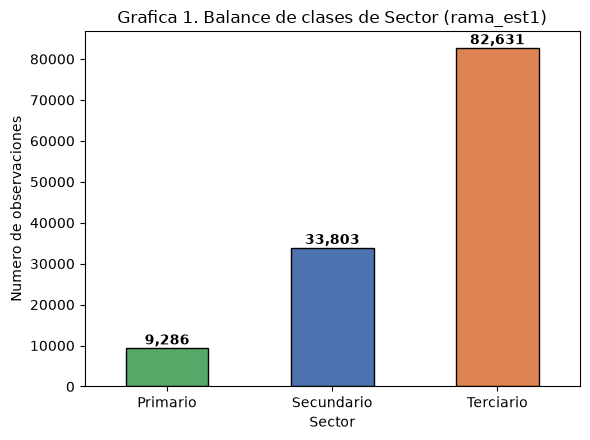

In [4]:
#Codigo hecho con claude
fig, ax = plt.subplots(figsize=(6, 4.5))
orden = ['Primario', 'Secundario', 'Terciario']
colores = ['#55A868', '#4C72B0', '#DD8452']
conteo.reindex(orden).plot(kind='bar', color=colores, edgecolor='black', ax=ax)
ax.set_xticklabels(orden, rotation=0)
ax.set_ylabel('Numero de observaciones')
ax.set_title('Grafica 1. Balance de clases de Sector (rama_est1)')
for i, v in enumerate(conteo.reindex(orden)):
    ax.text(i, v + 1000, f"{v:,}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

Aqui podemos ver el desbalance entre el terciario contra el secundario y primario.

Se ve claramente que las clases están bastante desbalanceadas: el sector terciario tiene el **65.7%** de las observaciones, el secundario el **26.9%**, y el primario solo el **7.4%** (hay casi 9 personas de servicios por cada persona del campo). Esto tiene sentido con lo que uno esperaría de la estructura económica de México actualmente (la mayoría de la población ocupada trabaja en comercio y servicios), pero tiene tres consecuencias importantes para la clasificación:

- **La exactitud engaña:** un modelo que siempre diga "terciario" ya tiene 65.7% de exactitud sin haber aprendido nada. Por eso la métrica principal es el F1 macro, y se incluye ese "modelo tonto" como referencia.
- **Los modelos tienden a ignorar a las clases chicas:** si no se corrige, a un modelo le "conviene" casi nunca predecir primario, porque equivocarse con el 7% cuesta poco en la exactitud total. Para compensar, en todos los modelos se usan pesos balanceados (`class_weight='balanced'` o equivalente), que hacen que equivocarse con una persona del sector primario cueste más.
- **Las particiones deben ser estratificadas:** para que el sector primario aparezca en la misma proporción en entrenamiento, prueba y en cada fold de la validación cruzada.

## Aspectos de la base que pueden influir en la clasificación

Antes de limpiar hay que revisar tres cosas que vienen de que esta es una encuesta real y no un dataset "de laboratorio":

1. **Códigos de no respuesta:** el INEGI no deja las no respuestas en blanco, las codifica con números (por ejemplo, 99 años de escolaridad). Para pandas son números válidos, así que si no se tratan el modelo va a creer que hay gente con 99 años de escuela.
2. **Columnas vacías o con huecos estructurales:** `p6c` y `n_hij` se leyeron como texto (`object`), señal de que tienen valores en blanco.
3. **Variables que "ya saben" el sector (fuga de datos):** algunas variables describen la unidad económica donde trabaja la persona, y podrían estar definidas a partir del propio sector.

In [5]:
print("anios_esc == 99 (no especificado):", (explor['anios_esc'] == 99).sum())
print("hrsocup == 0 (ocupado sin horas):  ", (explor['hrsocup'] == 0).sum())
print("hrsocup > 119 (mas de 17 h diarias):", (explor['hrsocup'] > 119).sum())
print()
print("Valores unicos de p6c:", explor['p6c'].unique())
print("Valores en blanco de n_hij:", (explor['n_hij'].astype(str).str.strip() == '').sum())

anios_esc == 99 (no especificado): 332
hrsocup == 0 (ocupado sin horas):   4958
hrsocup > 119 (mas de 17 h diarias): 15

Valores unicos de p6c: <StringArray>
[' ']
Length: 1, dtype: str
Valores en blanco de n_hij: 72507


- Hay **332 personas con `anios_esc = 99`** (escolaridad no especificada). Si no se quitan, el modelo creería que existen personas con 99 años de escuela.
- Hay **4,958 personas que reportan 0 horas trabajadas** pese a estar ocupadas y con ingreso, y 15 con más de 119 horas a la semana (más de 17 horas diarias, todos los días). Son casos contradictorios o poco realistas.
- `p6c` tiene un solo valor en toda la base: un espacio en blanco, o sea que está completamente vacía.
- `n_hij` tiene 72,507 valores en blanco en este subconjunto. En el proyecto de [regresión del ingreso laboral](../regresion-caso-real-enoe/README.md) se confirmó con una tabla cruzada que ese hueco coincide exactamente con los hombres: la pregunta de hijos nacidos vivos solo se le hace a mujeres, así que el faltante es estructural y no aleatorio.

In [6]:
# Proporcion de cada sector dentro de cada categoria de ambito2 y tue1
print("Sector segun ambito2 (proporcion por fila):")
print(pd.crosstab(explor['ambito2'], explor['Sector'], normalize='index').round(3))
print("\nSector segun tue1 (proporcion por fila):")
print(pd.crosstab(explor['tue1'], explor['Sector'], normalize='index').round(3))

Sector segun ambito2 (proporcion por fila):
Sector   Primario  Secundario  Terciario
ambito2                                 
0           0.655       0.112      0.233
2           0.000       0.417      0.583
3           0.000       0.239      0.761
4           0.000       0.108      0.892
5           0.000       0.237      0.763
6           0.000       0.647      0.353
7           0.000       0.000      1.000
8           0.000       0.000      1.000

Sector segun tue1 (proporcion por fila):
Sector  Primario  Secundario  Terciario
tue1                                   
1           0.14       0.289      0.571
2           0.00       0.043      0.957
3           0.00       0.319      0.681
4           0.00       0.500      0.500


Esta tabla es muy importante para decidir qué variables **no** usar:

- **`ambito2`:** el 100% de las personas del sector primario están en la categoría 0 (el ámbito agropecuario), y en todas las demás categorias la proporcion de primario es exactamente 0.000. Es decir, `ambito2` ya trae "escondido" si la persona trabaja en el campo.
- **`tue1`:** pasa lo mismo, en las categorías 2, 3 y 4 no hay nadie del sector primario; todo el primario cae en la categoría 1.

Si se metieran estas variables, el modelo detectaría el sector primario casi perfecto, pero no porque haya aprendido algo del perfil de las personas, sino porque estaría leyendo una variable que se construyó con el propio sector. Eso seria una **fuga de datos** y haría que las métricas se vieran mucho mejores de lo que realmente son. Por eso se dejan fuera.

# Preparación y tratamiento de los datos

## Limpieza

Se trabaja con la misma base y los mismos pasos de limpieza de los proyectos anteriores, un resumen de la limpieza que se ha ido perfeccipnando cada proyecto: en [regresión del ingreso laboral](../regresion-caso-real-enoe/README.md) y [clasificación de prestaciones laborales](../clasificacion-prestaciones-enoe/README.md) viene más detallado, pero aqui un resumen=

- **Se quitan las observaciones con `rama_est1 = 4`** (sector no especificado), porque no son una clase real.
- **Se quitan los 10 identificadores de la encuesta** (`r_def`, `c_res`, `cve_ent`, `con`, `upm`, `n_pro_viv`, `v_sel`, `n_hog`, `h_mud`, `n_ren`). Son la llave primaria y las banderas de control que se usaron para unir las tablas; ya cumplieron su función y el número de renglón dentro de un hogar no explica nada sobre el sector.
- **Se quitan `p6c` y `n_hij`:** `p6c` viene vacía en todas las observaciones, y además es el propio ingreso discretizado (fuga de datos). `n_hij` solo se le pregunta a mujeres, así que tiene un hueco estructural del tamaño de todos los hombres de la muestra, y no tiene caso imputarlo.
- **Se quitan las observaciones con escolaridad no especificada** (`anios_esc = 99`), porque son pocas frente al tamaño de la muestra y es mejor eliminarlas que inventarles un valor.
- **Se quitan las observaciones con horas trabajadas poco realistas:** 0 horas (son personas ocupadas que reportan ingreso, así que 0 horas es un caso contradictorio) o más de 119 horas a la semana (más de 17 horas diarias todos los días).
- **No se eliminan outliers de ingreso, edad ni escolaridad.** Aunque el método de Tukey marca como atípicos a los ingresos muy altos o a la gente mayor que sigue trabajando, son valores reales (hay personas con ingresos altos, con posgrado o que trabajan a los 80 años), no errores de captura.
- **Se recodifican `sex` y `ur` a 0/1** (`sex01`: 0 = hombre, 1 = mujer; `ur01`: 0 = urbano, 1 = rural) y **se calcula el logaritmo del ingreso** (`log_ingocup`), que se usa en los modelos sensibles a la escala.

In [7]:
sub = df[df['rama_est1'].isin([1, 2, 3])].copy()          # se quita el codigo 4 (no especificado)
sub['Sector'] = sub['rama_est1'].map(sector_map)

ids = ['r_def', 'c_res', 'cve_ent', 'con', 'upm', 'n_pro_viv',
       'v_sel', 'n_hog', 'h_mud', 'n_ren']
sub = sub.drop(columns=ids + ['p6c', 'n_hij'])

sub = sub[sub['anios_esc'] != 99]                             # anios_esc no especificado
sub = sub[(sub['hrsocup'] <= 119) & (sub['hrsocup'] != 0)]    # horas trabajadas poco realistas

sub['sex01'] = sub['sex'].replace({1: 0, 2: 1})   # 0 = hombre, 1 = mujer
sub['ur01'] = sub['ur'].replace({1: 0, 2: 1})     # 0 = urbano, 1 = rural
sub['log_ingocup'] = np.log(sub['ingocup'])       # log de ingreso (para modelos sensibles a la escala)

print("Shape final tras limpieza:", sub.shape)
print(sub['Sector'].value_counts())

Shape final tras limpieza: (120430, 22)
Sector
Terciario     79025
Secundario    32355
Primario       9050
Name: count, dtype: int64


Se llega a las mismas **120,430 observaciones** de los proyectos [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md) y [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md) (79,025 terciario, 32,355 secundario y 9,050 primario), con 22 columnas. Se quitaron 5,796 personas en total (el 4.6% de la base), la mayoría por tener 0 horas trabajadas. Las proporciones de cada sector casi no cambian (65.6% / 26.9% / 7.5%), así que la limpieza no cambió el balance de clases.

## Selección de variables explicativas

De las variables que quedan, solo se usan 6: `eda`, `anios_esc`, `hrsocup`, `ingocup` (o `log_ingocup`), `sex01` y `ur01`. La razón es que la pregunta del proyecto es si el **perfil sociodemográfico** de una persona determina el sector en el que trabaja, así que se quieren variables que describan a la persona y no al lugar donde trabaja:

- **`ambito2` y `tue1` se excluyen por fuga de datos.** Como se vio en la exploración, el 100% de las personas del sector primario caen en una sola categoría de `ambito2` (la agropecuaria) y en una sola de `tue1`, y nadie de las demás categorías es del sector primario. Es decir, estas variables están construidas con información del propio sector: el modelo "adivinaría" el sector primario leyendo su definición, no aprendiendo un patrón.
- **`niv_ins` se excluye por redundante:** mide la escolaridad igual que `anios_esc` pero en solo 4 categorías (correlación de alrededor de 0.9 en los proyectos anteriores), así que `anios_esc` tiene la misma información pero más fina.
- **`seg_soc`, `imssissste`, `p6d`, `emp_ppal` y `pre_asa`** describen la formalidad y las prestaciones del empleo, no a la persona. Además están muy correlacionadas entre sí (entre 0.88 y 1.00 en el proyecto de [regresión del ingreso laboral](../regresion-caso-real-enoe/README.md)) y `pre_asa` tiene más del 25% de casos "no aplica".
- **`pos_ocu`, `zona` y `e_con`** casi no cambian la proporción de cada sector entre sus categorías, así que aportan muy poca información para distinguir sectores y sí agregarían ruido.

## ¿El dataset sirve para estos modelos?

Antes de entrenar hay que confirmar un par de cosas que estos modelos necesitsn:

- **Sin valores faltantes ni infinitos:** ninguno de los modelos (en su implementación de sklearn/Keras) acepta valores faltantes.
- **Escala de las variables:** la regresión logística, LDA, la SVM y la red neuronal trabajan con distancias y gradientes, así que si una variable tiene una escala mucho más grande que las demás (como el ingreso, que llega a 250,000) va a dominar al modelo. Para estos modelos se usa el logaritmo del ingreso y se estandarizan todas las variables. Los modelos basados en árboles (árbol, Random Forest y Boosting) no se ven afectados por la escala, así que usan las variables tal cual.

In [8]:
vars_base = ['eda', 'anios_esc', 'hrsocup', 'ingocup', 'log_ingocup', 'sex01', 'ur01']

print("Valores faltantes por variable:")
print(sub[vars_base + ['rama_est1']].isna().sum())
print("\nValores infinitos en log_ingocup:", np.isinf(sub['log_ingocup']).sum())
print("Ingreso minimo:", sub['ingocup'].min())
print()
print(sub[vars_base].describe().T.round(2))

Valores faltantes por variable:
eda            0
anios_esc      0
hrsocup        0
ingocup        0
log_ingocup    0
sex01          0
ur01           0
rama_est1      0
dtype: int64

Valores infinitos en log_ingocup: 0
Ingreso minimo: 2

                count      mean      std    min      25%      50%       75%  \
eda          120430.0     40.24    14.21  12.00    29.00    39.00     51.00   
anios_esc    120430.0     10.66     4.16   0.00     9.00    11.00     12.00   
hrsocup      120430.0     41.45    16.61   1.00    32.00    45.00     48.00   
ingocup      120430.0  11181.50  8940.77   2.00  6450.00  9460.00  13000.00   
log_ingocup  120430.0      9.07     0.77   0.69     8.77     9.15      9.47   
sex01        120430.0      0.42     0.49   0.00     0.00     0.00      1.00   
ur01         120430.0      0.38     0.48   0.00     0.00     0.00      1.00   

                   max  
eda              98.00  
anios_esc        24.00  
hrsocup         119.00  
ingocup      250000.00  
log_i

No hay ningún valor faltante ni infinito (el ingreso mínimo es 2 pesos, así que el logaritmo siempre existe). También se ve que `ingocup` tiene una escala muchísimo más grande (promedio de 11,181 y máximo de 250,000) que las demás variables, y está muy sesgada a la derecha (el promedio es mucho mayor que la mediana de 9,460), por eso para los modelos sensibles a la escala se usa `log_ingocup`, que tiene un rango mucho más compacto (0.69 a 12.43). Las dos variables binarias están razonablemente repartidas: 42% de la muestra son mujeres y 38% vive en localidades rurales. Con esto, el dataset está listo para todos los modelos.

## Partición de train test

Se usa **exactamente la misma partición** que en los proyectos [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md) y [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md): 80% entrenamiento y 20% prueba, estratificada por sector y con la misma semilla (`random_state=67`). `stratify` obliga a que la partición aleatoria se haga dentro de cada clase por separado, para que el sector primario (la clase más chica) quede representado en la misma proporción en los dos subconjuntos.

Desde este punto, **todo el análisis de relaciones entre variables, la selección de hiperparámetros y la comparación de modelos se hace solo con `train`**; `test` se queda guardado hasta la evaluación del modelo final.

In [9]:
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency

datos = sub[vars_base + ['rama_est1', 'Sector']].copy()

train, test = train_test_split(
    datos, train_size=0.8, random_state=67,
    stratify=datos['rama_est1']
)
print("Entrenamiento:", train.shape)
print("Prueba:       ", test.shape)

conteos_split = pd.DataFrame({
    'Entrenamiento': train['Sector'].value_counts().sort_index(),
    'Prueba': test['Sector'].value_counts().sort_index()
})
conteos_split['% Entrenamiento'] = (conteos_split['Entrenamiento'] / conteos_split['Entrenamiento'].sum() * 100).round(2)
conteos_split['% Prueba'] = (conteos_split['Prueba'] / conteos_split['Prueba'].sum() * 100).round(2)
print()
print(conteos_split)

chi2, p_valor, dof, esperado = chi2_contingency(conteos_split[['Entrenamiento', 'Prueba']].T)
print(f"\nchi2 = {chi2:.4f}   p-value = {p_valor:.4f}")

Entrenamiento: (96344, 9)
Prueba:        (24086, 9)

            Entrenamiento  Prueba  % Entrenamiento  % Prueba
Sector                                                      
Primario             7240    1810             7.51      7.51
Secundario          25884    6471            26.87     26.87
Terciario           63220   15805            65.62     65.62

chi2 = 0.0000   p-value = 1.0000


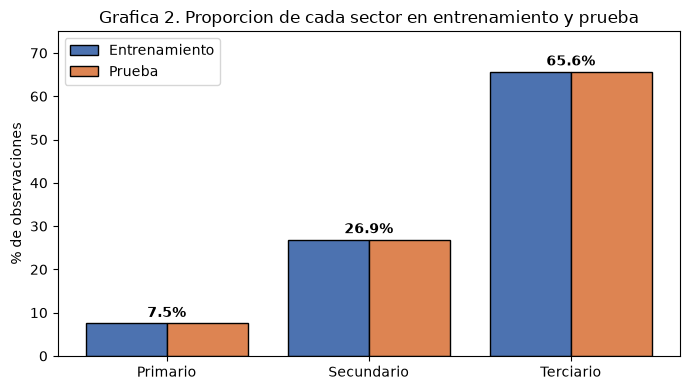

In [10]:
#Codigo hecho con claude
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(conteos_split))
ax.bar(x - 0.2, conteos_split['% Entrenamiento'], width=0.4, color='#4C72B0', edgecolor='black', label='Entrenamiento')
ax.bar(x + 0.2, conteos_split['% Prueba'], width=0.4, color='#DD8452', edgecolor='black', label='Prueba')
for i, v in enumerate(conteos_split['% Entrenamiento']):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(conteos_split.index)
ax.set_ylabel('% de observaciones')
ax.set_ylim(0, 75)
ax.set_title('Grafica 2. Proporcion de cada sector en entrenamiento y prueba')
ax.legend()
plt.tight_layout()
plt.show()

Quedan **96,344 personas en entrenamiento y 24,086 en prueba**. Las proporciones son idénticas en los dos subconjuntos (7.51% primario, 26.87% secundario, 65.62% terciario), y la prueba ji-cuadrada da un p-value de 1.0, así que no hay ninguna evidencia de que la composición de clases dependa del subconjunto. Si más adelante el modelo final tiene métricas distintas en validación cruzada y en prueba, va a ser por cómo generaliza, no porque los subconjuntos sean distintos.

## Relación de las variables con el sector (solo entrenamiento)

Ahora sí se revisa cómo se relaciona cada variable explicativa con el sector, usando únicamente el set de entrenamiento. Primero las 4 variables continuas: su promedio y desviación estándar dentro de cada sector.

In [11]:
vars_cont = ['eda', 'anios_esc', 'hrsocup', 'log_ingocup']
print("Promedio por clase:")
print(train.groupby('Sector')[vars_cont + ['ingocup']].mean().round(3))
print()
print("Mediana del ingreso mensual por clase:")
print(train.groupby('Sector')['ingocup'].median())
print()
print("Desviacion estandar por clase:")
print(train.groupby('Sector')[vars_cont].std().round(3))

Promedio por clase:
               eda  anios_esc  hrsocup  log_ingocup    ingocup
Sector                                                        
Primario    43.249      7.287   39.230        8.570   7344.552
Secundario  39.085      9.897   43.404        9.202  12013.149
Terciario   40.376     11.363   40.884        9.075  11281.393

Mediana del ingreso mensual por clase:
Sector
Primario       6450.0
Secundario    10750.0
Terciario      9460.0
Name: ingocup, dtype: float64

Desviacion estandar por clase:
               eda  anios_esc  hrsocup  log_ingocup
Sector                                             
Primario    16.703      3.881   15.811        0.914
Secundario  13.584      3.821   13.238        0.677
Terciario   14.074      4.082   17.841        0.761


**Sobre el promedio (qué tan distintas son las clases entre sí):**

- Primario tiene el promedio de edad más alto (43.2 años) y de escolaridad más bajo (7.3 años): gente mayor y con menos estudios, consistente con el trabajo de campo. También es el que menos gana, con una mediana de **6,450 pesos** al mes, contra 10,750 del secundario y 9,460 del terciario.
- Secundario y Terciario se parecen mucho más entre sí: escolaridad de 9.9 y 11.4 años, e ingresos parecidos (el secundario gana un poco más en mediana). Esto ya anticipa que **separar industria de servicios va a ser lo más difícil**.
- Secundario es el que más horas trabaja en promedio (43.4), un poco por encima de Terciario (40.9) y de Primario (39.2).

**Sobre la desviación estándar:**

- En `eda` el primario tiene una dispersión de 16.7 contra 13.6 del secundario (casi 25% más), y en `hrsocup` el terciario tiene 17.8 contra 13.2 del secundario. Es decir, la variabilidad no es igual entre sectores, que es justo el supuesto de homocedasticidad que necesita LDA. Esto no invalida LDA, pero sí indica que no es el modelo ideal para estos datos.

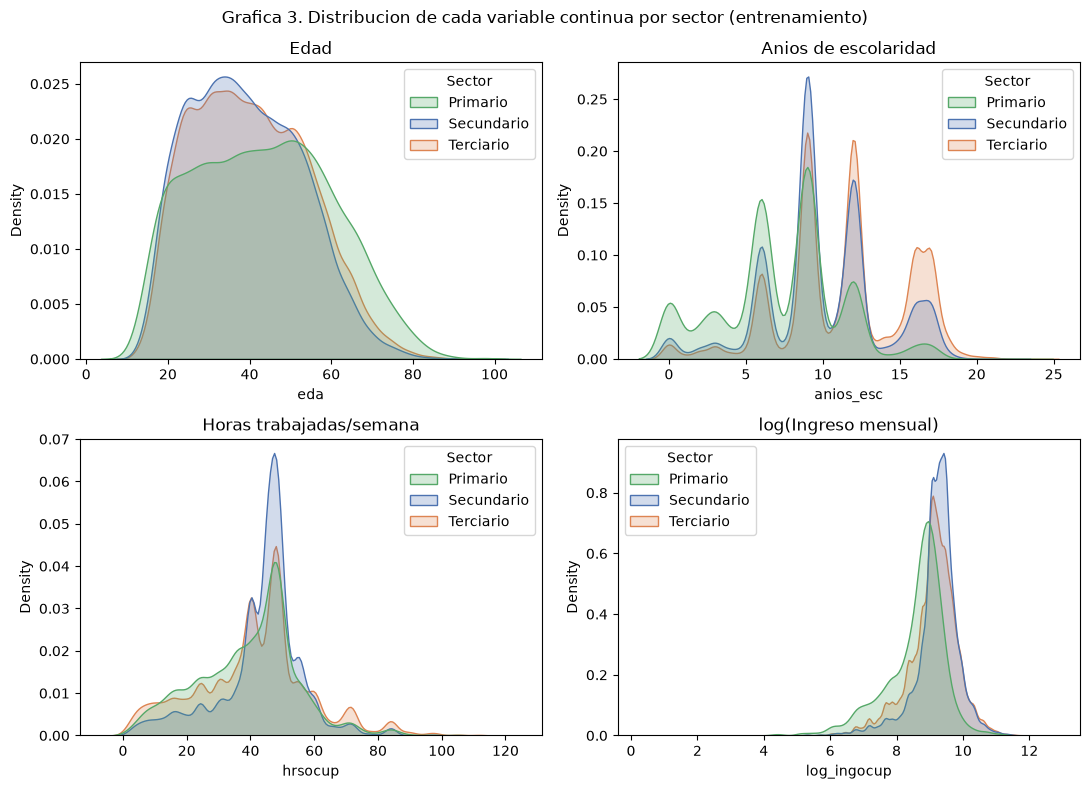

In [12]:
#Codigo hecho con claude
nombres_cont = {'eda': 'Edad', 'anios_esc': 'Anios de escolaridad',
                'hrsocup': 'Horas trabajadas/semana', 'log_ingocup': 'log(Ingreso mensual)'}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, var in zip(axes.ravel(), vars_cont):
    sns.kdeplot(data=train, x=var, hue='Sector', hue_order=['Primario', 'Secundario', 'Terciario'],
                palette=['#55A868', '#4C72B0', '#DD8452'], fill=True, alpha=0.25,
                common_norm=False, ax=ax)
    ax.set_title(nombres_cont[var])
plt.suptitle('Grafica 3. Distribucion de cada variable continua por sector (entrenamiento)')
plt.tight_layout()
plt.show()

- **Escolaridad** es la variable continua que mejor separa al primario. Las curvas tienen "picos" en 6, 9, 12 y 16 años porque son los niveles terminados (primaria, secundaria, preparatoria y licenciatura). El primario tiene mucho más peso en 0 a 6 años (incluso un pico en 0, personas que nunca fueron a la escuela); el secundario tiene su pico más alto en 9 años (secundaria terminada); y el terciario es el que más se concentra en 12 y en 16 años o más.
- **Ingreso (en logaritmo):** el primario está corrido a la izquierda (gana menos y tiene una cola larga de ingresos muy bajos), pero las curvas de secundario y terciario prácticamente se enciman.
- **Edad:** el primario está un poco corrido hacia edades mayores (tiene más personas de 50 a 80 años), mientras que secundario y terciario se ven casi iguales.
- **Horas trabajadas:** los 3 sectores tienen su pico en la jornada estándar de 40 a 48 horas; el secundario es el que más se concentra ahí, y el terciario tiene más personas con jornadas cortas (tiempo parcial) y también con jornadas muy largas.

En general, las curvas se enciman bastante: **ninguna variable continua por sí sola separa bien a los 3 sectores**, sobre todo a secundario de terciario.

Ahora las 2 variables binarias. Para cada grupo (urbano/rural y hombre/mujer) se calcula qué porcentaje trabaja en cada sector.

% de cada sector segun tipo de localidad:
Sector  Primario  Secundario  Terciario
ur01                                   
Rural       18.6        27.2       54.2
Urbano       0.9        26.7       72.5

% de cada sector segun sexo:
Sector  Primario  Secundario  Terciario
sex01                                  
Hombre      11.4        33.7       54.9
Mujer        2.2        17.4       80.4

% de personas rurales dentro de cada sector:
Sector
Primario      92.9
Secundario    37.9
Terciario     31.0
Name: ur01, dtype: float64

% de mujeres dentro de cada sector:
Sector
Primario      12.5
Secundario    27.3
Terciario     51.5
Name: sex01, dtype: float64


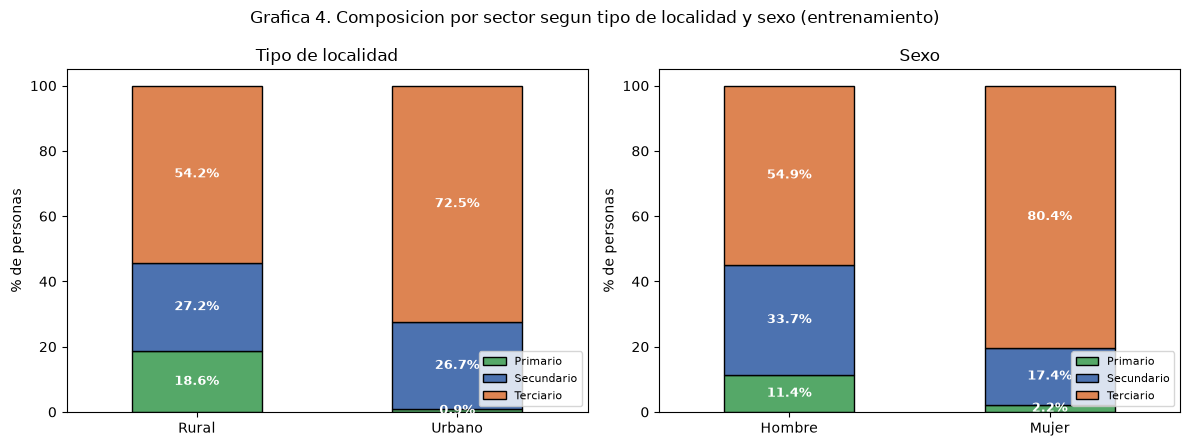

In [13]:
#Codigo hecho con claude
tab_ur = pd.crosstab(train['ur01'].map({0: 'Urbano', 1: 'Rural'}), train['Sector'], normalize='index') * 100
tab_sex = pd.crosstab(train['sex01'].map({0: 'Hombre', 1: 'Mujer'}), train['Sector'], normalize='index') * 100
print("% de cada sector segun tipo de localidad:")
print(tab_ur.round(1))
print("\n% de cada sector segun sexo:")
print(tab_sex.round(1))
print("\n% de personas rurales dentro de cada sector:")
print((train.groupby('Sector')['ur01'].mean() * 100).round(1))
print("\n% de mujeres dentro de cada sector:")
print((train.groupby('Sector')['sex01'].mean() * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, tab, titulo in zip(axes, [tab_ur, tab_sex], ['Tipo de localidad', 'Sexo']):
    tab[['Primario', 'Secundario', 'Terciario']].plot(kind='bar', stacked=True, ax=ax,
                                                       color=['#55A868', '#4C72B0', '#DD8452'], edgecolor='black')
    for i, fila in enumerate(tab[['Primario', 'Secundario', 'Terciario']].values):
        acumulado = 0
        for v in fila:
            ax.text(i, acumulado + v / 2, f"{v:.1f}%", ha='center', va='center', fontsize=9, color='white', fontweight='bold')
            acumulado += v
    ax.set_title(titulo)
    ax.set_ylabel('% de personas')
    ax.set_xlabel('')
    ax.set_xticklabels(tab.index, rotation=0)
    ax.legend(loc='lower right', fontsize=8)
plt.suptitle('Grafica 4. Composicion por sector segun tipo de localidad y sexo (entrenamiento)')
plt.tight_layout()
plt.show()

Aquí sí aparecen diferencias muy grandes:

- **Tipo de localidad:** en las localidades rurales el **18.6%** trabaja en el sector primario, contra solo el **0.9%** en las urbanas. Visto al revés, el **92.9% de las personas del sector primario viven en una localidad rural**. Es la variable que más claramente identifica al sector primario.
- **Sexo:** el 80.4% de las mujeres ocupadas trabaja en servicios, contra 54.9% de los hombres. Los hombres están mucho más presentes en el campo (11.4% contra 2.2%) y en la industria (33.7% contra 17.4%). Solo el 12.5% de las personas del sector primario son mujeres, y en el terciario son la mitad (51.5%).

Esto ya anticipa que **las dos variables binarias van a ser de las más importantes**, y que un modelo que no las pueda usar (como LDA) va a estar en desventaja.

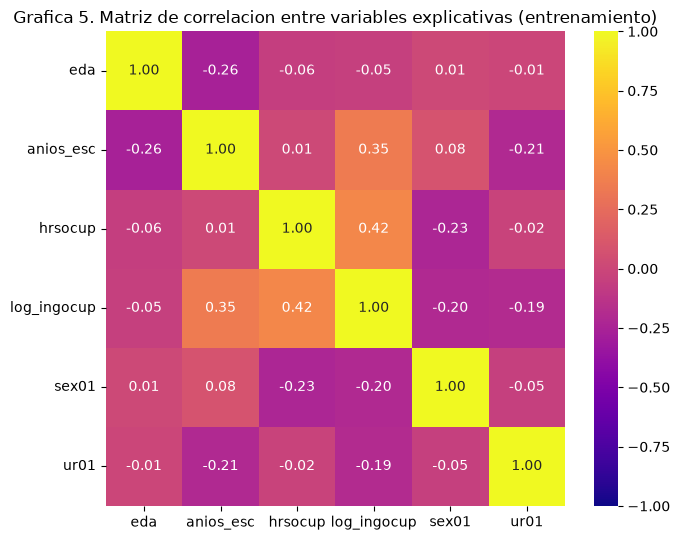

In [14]:
#Codigo hecho con claude
corr_train = train[['eda', 'anios_esc', 'hrsocup', 'log_ingocup', 'sex01', 'ur01']].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_train, annot=True, fmt=".2f", cmap="plasma", vmin=-1, vmax=1)
plt.title("Grafica 5. Matriz de correlacion entre variables explicativas (entrenamiento)")
plt.tight_layout()
plt.show()

Las correlaciones entre las variables explicativas son bajas o moderadas: la más alta es entre `log_ingocup` y `hrsocup` (0.42; quien trabaja más horas gana más), seguida de `log_ingocup` con `anios_esc` (0.35) y `eda` con `anios_esc` (-0.26; las personas mayores estudiaron menos años). Ningún par pasa de 0.5, así que **no hay problemas de colinealidad** y cada variable aporta información distinta.

## Conjuntos de variables por tipo de modelo

Se preparan dos versiones de las variables explicativas:

- **Para el árbol, Random Forest y Boosting:** las 6 variables originales (con `ingocup` sin transformar).
- **Para la regresión logística, LDA, la SVM y la red neuronal:** las 6 variables con `log_ingocup`, estandarizadas (media 0, desviación estándar 1). LDA solo usa las 4 continuas, porque sus supuestos de normalidad no tienen sentido con variables binarias.

Un detalle importante: el `StandardScaler` se ajusta **solo con los datos con los que se entrena**. En la validación cruzada esto significa que se ajusta dentro de cada fold (con un `Pipeline`), para que el fold de validación no "filtre" información al escalamiento; y para el modelo final se ajusta con todo el set de entrenamiento y después se aplica al de prueba.

In [15]:
from sklearn.preprocessing import StandardScaler

clases = ['Primario', 'Secundario', 'Terciario']

# Variables "crudas" (para los modelos basados en arboles, no les afecta la escala)
vars_arbol = ['eda', 'anios_esc', 'hrsocup', 'ingocup', 'sex01', 'ur01']
# Variables para modelos sensibles a la escala (logistica, LDA, SVM, red neuronal)
vars_escala = ['eda', 'anios_esc', 'hrsocup', 'log_ingocup', 'sex01', 'ur01']
vars_lda = ['eda', 'anios_esc', 'hrsocup', 'log_ingocup']

X_train_a, X_test_a = train[vars_arbol], test[vars_arbol]
X_train_e, X_test_e = train[vars_escala], test[vars_escala]   # sin escalar (el escalador va dentro del pipeline)
y_train, y_test = train['rama_est1'], test['rama_est1']

# Version escalada de todo el entrenamiento (solo para la seleccion de hiperparametros de la SVM y la red)
scaler = StandardScaler().fit(X_train_e)
X_train_s = pd.DataFrame(scaler.transform(X_train_e), columns=vars_escala, index=train.index)
print("Promedio (train, escalado):", X_train_s.mean().round(3).tolist())
print("Desv. est. (train, escalado):", X_train_s.std().round(3).tolist())

Promedio (train, escalado): [-0.0, -0.0, -0.0, -0.0, 0.0, 0.0]
Desv. est. (train, escalado): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


Aquí podemos ver que el escalamiento funcionó bien. Todas las variables quedaron con **promedio 0** y **desviación estándar 1** en el set de entrenamiento (el `-0.0` es un número negativo muy muy chico que por el redondeo se ve así, pero es lo mismo que 0). Antes el ingreso se medía en miles de pesos y la escolaridad en años, entonces el ingreso hubiera "pesado" más solo por tener números más grandes. Esta versión escalada de todo el entrenamiento solo se usa para elegir los hiperparámetros de la SVM y para el entrenamiento de ejemplo de la red; en la validación cruzada el escalador se vuelve a ajustar dentro de cada fold.

# COnstrucción de modelos

Se van a construir los 7 modelos. Para cada uno se describen sus hiperparámetros y, cuando hay que elegir alguno, se elige **solo con el set de entrenamiento**. La comparación de desempeño entre todos se hace en la siguiente sección, con validación cruzada.

Primero se definen los 5 folds que se van a usar para comparar a **todos** los modelos (los mismos para todos, para que la comparación sea justa), y una función que, para un modelo dado, lo entrena en 4 folds, lo evalúa en el que queda fuera, y repite 5 veces. En cada fold guarda la exactitud, la precisión, la sensibilidad y el F1 macro en validación, el F1 macro en entrenamiento (para revisar sobreajuste), el tiempo de entrenamiento, y las predicciones de validación (para después armar la matriz de confusión fuera de fold para cada modelo).

In [16]:
#Codigo hecho con claude
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
folds = list(skf5.split(X_train_a, y_train))
print("Tamano de cada fold (entrenamiento / validacion):")
for i, (tr, va) in enumerate(folds, start=1):
    print(f"  Fold {i}: {len(tr):,} / {len(va):,}")

cv_folds = {}   # metricas por fold de cada modelo
oof = {}        # predicciones fuera de fold (cada observacion predicha por el modelo que no la vio)

def predecir_sklearn(modelo, X):
    return modelo.predict(X)

def validacion_cruzada(nombre, entrenar, X, predecir=predecir_sklearn, n_sub=None):
    """entrenar(X_tr, y_tr) -> modelo ya entrenado. n_sub: submuestra del fold de entrenamiento (para la SVM)."""
    filas = []
    pred_oof = pd.Series(0, index=y_train.index)
    for i, (tr, va) in enumerate(folds, start=1):
        X_tr, y_tr = X.iloc[tr], y_train.iloc[tr]
        if n_sub is not None:
            X_tr, _, y_tr, _ = train_test_split(X_tr, y_tr, train_size=n_sub,
                                                random_state=67, stratify=y_tr)
        t0 = time.time()
        modelo = entrenar(X_tr, y_tr)
        seg = time.time() - t0
        p_va = predecir(modelo, X.iloc[va])
        p_tr = predecir(modelo, X_tr)
        y_va = y_train.iloc[va]
        pred_oof.iloc[va] = p_va
        filas.append({'Fold': i,
                      'Exactitud': accuracy_score(y_va, p_va),
                      'Precision (macro)': precision_score(y_va, p_va, average='macro'),
                      'Sensibilidad (macro)': recall_score(y_va, p_va, average='macro'),
                      'F1-score (macro)': f1_score(y_va, p_va, average='macro'),
                      'F1 macro entrenamiento': f1_score(y_tr, p_tr, average='macro'),
                      'Tiempo (s)': seg})
    cv_folds[nombre] = pd.DataFrame(filas).set_index('Fold')
    oof[nombre] = pred_oof
    res = cv_folds[nombre]
    print(f"=== {nombre} ===")
    print(res.round(4).to_string())
    print(f"\nF1 macro (validacion): {res['F1-score (macro)'].mean():.4f} +/- {res['F1-score (macro)'].std():.4f}")
    print(f"Exactitud (validacion): {res['Exactitud'].mean():.4f} +/- {res['Exactitud'].std():.4f}")
    print(f"F1 macro (entrenamiento): {res['F1 macro entrenamiento'].mean():.4f}")

Tamano de cada fold (entrenamiento / validacion):
  Fold 1: 77,075 / 19,269
  Fold 2: 77,075 / 19,269
  Fold 3: 77,075 / 19,269
  Fold 4: 77,075 / 19,269
  Fold 5: 77,076 / 19,268


## Modelo de referencia (siempre "terciario")

Antes de los modelos de verdad, conviene tener un piso: un "modelo" que no aprende nada y siempre predice la clase más común. Cualquier modelo que valga la pena tiene que superarlo con claridad, sobre todo en F1 macro.

In [17]:
from sklearn.dummy import DummyClassifier

validacion_cruzada('Referencia (siempre terciario)',
                   lambda X, y: DummyClassifier(strategy='most_frequent').fit(X, y),
                   X_train_a)

=== Referencia (siempre terciario) ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.6562             0.2187                0.3333            0.2641                  0.2641      0.0011
2        0.6562             0.2187                0.3333            0.2641                  0.2641      0.0011
3        0.6562             0.2187                0.3333            0.2641                  0.2641      0.0011
4        0.6562             0.2187                0.3333            0.2641                  0.2641      0.0011
5        0.6562             0.2187                0.3333            0.2641                  0.2641      0.0011

F1 macro (validacion): 0.2641 +/- 0.0000
Exactitud (validacion): 0.6562 +/- 0.0000
F1 macro (entrenamiento): 0.2641


Como se esperaba, el modelo de referencia tiene **65.6% de exactitud** pero un **F1 macro de solo 0.264**: le atina a todos los de terciario y a ninguno de primario ni de secundario. Este es el piso. Cualquier modelo tiene que estar claramente arriba de 0.264 en F1 macro para que valga la pena, aunque su exactitud sea menor que 65.6% (y va a pasar: al darle más peso a las clases chicas, los modelos sacrifican un poco de exactitud a cambio de detectar a primario y secundario).

Todo esto es para poder comparar a todos los otros modelos, ya que si tenemos uno con menjor exactitud tenemos que compararlo con est para que sepamos que el modelo si hizo algo más significativio

## Regresión logística

Se usa `LogisticRegression` de sklearn (que con 3 clases ajusta la versión multinomial) con las 6 variables estandarizadas:

- `class_weight='balanced'`: pondera la función de verosimilitud dándole más peso a las observaciones de las clases minoritarias, para que el modelo no se dedique a predecir solo "terciario". Este mismo criterio se usa en todos los modelos para que la comparación sea justa.
- `max_iter=1000`: suficientes iteraciones para que el optimizador converja.
- No se ajusta ningún otro hiperparámetro: la idea de este modelo es ser un punto de comparación lineal y sencillo.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def entrenar_logreg(X, y):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000)).fit(X, y)

validacion_cruzada('Regresion logistica', entrenar_logreg, X_train_e)

=== Regresion logistica ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.5551             0.4851                0.6130            0.4919                  0.4894      0.0546
2        0.5512             0.4813                0.6045            0.4869                  0.4907      0.0561
3        0.5563             0.4855                0.6120            0.4932                  0.4898      0.0549
4        0.5555             0.4833                0.6079            0.4902                  0.4908      0.0609
5        0.5544             0.4833                0.6081            0.4883                  0.4906      0.0663

F1 macro (validacion): 0.4901 +/- 0.0025
Exactitud (validacion): 0.5545 +/- 0.0019
F1 macro (entrenamiento): 0.4903


La regresión logística obtiene un **F1 macro de 0.490** en promedio, casi el doble que la referencia, con una desviación estándar muy chica entre folds (0.0025). Su exactitud (55.5%) es menor que la de la referencia, por lo que se explicó arriba: los pesos balanceados la hacen predecir primario y secundario más seguido, y eso le cuesta aciertos en terciario. El F1 en entrenamiento (0.490) es prácticamente igual al de validación (0.490), así que **no hay sobreajuste**; su limitación es de sesgo, porque una frontera lineal no tiene suficiente flexibilidad para separar sectores que se traslapan tanto.

## LDA

Se usa `LinearDiscriminantAnalysis` con las **4 variables continuas** estandarizadas (`eda`, `anios_esc`, `hrsocup` y `log_ingocup`), porque `sex01` y `ur01` son binarias y claramente no normales, así que no son coherentes con los supuestos del modelo. Se usan **probabilidades a priori uniformes** (`priors=[1/3, 1/3, 1/3]`): en el proyecto [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md) se vio que con las priors por default (las proporciones observadas) LDA casi nunca predice "primario", porque el 65% de los datos son terciario y eso "jala" todas las decisiones hacia esa clase. Con priors iguales, la decisión depende solo de qué tan cerca está la persona del centro de cada sector.

En la sección de exploración (Gráfica 3 y la tabla de desviaciones estándar) ya se vio que los supuestos se cumplen solo a medias: las distribuciones son aproximadamente acampanadas pero no simétricas, y la dispersión de `eda` y `hrsocup` cambia bastante entre sectores (no hay homocedasticidad perfecta).|

In [19]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

def entrenar_lda(X, y):
    return make_pipeline(StandardScaler(), LDA(priors=[1/3, 1/3, 1/3])).fit(X, y)

validacion_cruzada('LDA', entrenar_lda, train[vars_lda])

=== LDA ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.4957             0.4537                0.5321            0.4396                  0.4355      0.0131
2        0.5005             0.4538                0.5328            0.4423                  0.4360      0.0186
3        0.4926             0.4456                0.5163            0.4322                  0.4377      0.0186
4        0.4950             0.4478                0.5211            0.4353                  0.4368      0.0219
5        0.4906             0.4459                0.5180            0.4318                  0.4372      0.0164

F1 macro (validacion): 0.4362 +/- 0.0046
Exactitud (validacion): 0.4949 +/- 0.0037
F1 macro (entrenamiento): 0.4366


LDA queda con un **F1 macro de 0.436** y una exactitud de 49.5%, por debajo de la regresión logística. Tampoco sobreajusta (0.437 en entrenamiento contra 0.436 en validación). Esto confirma lo que se vio en el proyecto [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md): el problema principal de LDA no es tanto que sus supuestos se cumplan solo a medias, sino que **no puede usar `ur01` ni `sex01`**, que en la exploración resultaron ser las variables que más separan a los sectores.

## Árbol de decisión podado

Se usa `DecisionTreeClassifier` con las 6 variables sin escalar y `class_weight='balanced'`. El hiperparámetro importante es $\alpha$ (`ccp_alpha`), que controla qué tanto se poda el árbol.

Para encontrar el valor óptimo de $\alpha$ se usa validación cruzada de 4 folds (`StratifiedKFold`), evaluando distintos valores de $\alpha$ y quedándose con el que da, en promedio, el mejor F1-score macro. Por eficiencia computacional, la búsqueda se hace sobre una **submuestra estratificada de 25,000 observaciones** del set de entrenamiento (igual que en el proyecto [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md)). Esta búsqueda es independiente de los 5 folds de la comparación, y usa solo datos de entrenamiento.

In [20]:
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.model_selection import cross_val_score

Xt_sub, _, yt_sub, _ = train_test_split(
    X_train_a, y_train, train_size=25000, random_state=67, stratify=y_train
)

skf4 = StratifiedKFold(n_splits=4, shuffle=True, random_state=67)
ccp = np.linspace(0.00001, 0.004, 60)

cv_scores = []
for alpha in ccp:
    t = DTC(random_state=67, class_weight='balanced', ccp_alpha=alpha)
    cv_scores.append(np.mean(cross_val_score(t, Xt_sub, yt_sub, cv=skf4, scoring='f1_macro')))
cv_scores = np.array(cv_scores)

alpha_optimo = ccp[np.argmax(cv_scores)]
print("Mejor alpha:", alpha_optimo)
print("Mejor F1 macro (CV):", cv_scores.max())

Mejor alpha: 0.00041576271186440685
Mejor F1 macro (CV): 0.5388025209412122


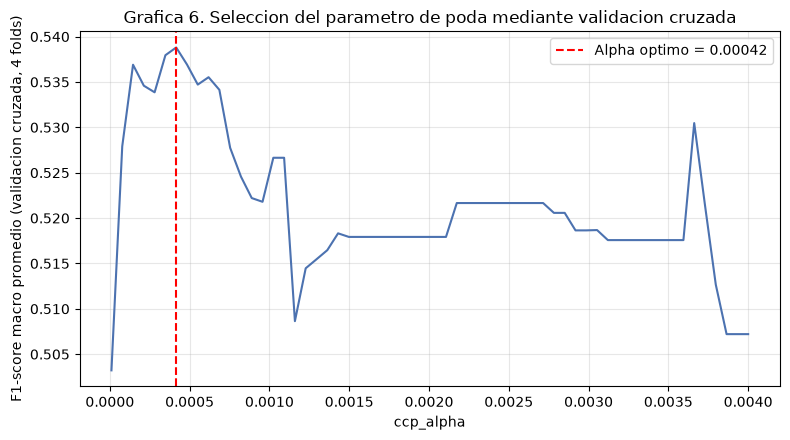

In [21]:
#Codigo hecho con claude
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ccp, cv_scores, color='#4C72B0')
ax.axvline(alpha_optimo, color='red', linestyle='--', label=f'Alpha optimo = {alpha_optimo:.5f}')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('F1-score macro promedio (validacion cruzada, 4 folds)')
ax.set_title('Grafica 6. Seleccion del parametro de poda mediante validacion cruzada')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se ve el comportamiento esperado de cost-complexity pruning: con $\alpha$ muy chico (casi sin podar) el desempeño en validación cruzada no es el mejor posible (el árbol grande se sobreajusta incluso dentro de cada fold), el F1 macro sube rápidamente hasta un máximo alrededor de $\alpha \approx 0.0004$, y después empieza a bajar (y luego se aplana en escalones) conforme $\alpha$ sigue subiendo y el árbol se vuelve cada vez más pequeño y con menos capacidad de distinguir entre clases. El valor óptimo encontrado es $\alpha \approx 0.00042$ (F1 macro de 0.539), el mismo que en el proyecto [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md), lo que confirma que se está trabajando con los mismos datos.

In [22]:
def entrenar_arbol(X, y):
    return DTC(random_state=67, class_weight='balanced', ccp_alpha=alpha_optimo).fit(X, y)

validacion_cruzada('Arbol de decision', entrenar_arbol, X_train_a)

=== Arbol de decision ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.5890             0.5231                0.6453            0.5379                  0.5341      0.9298
2        0.5884             0.5193                0.6323            0.5361                  0.5449      0.9358
3        0.6091             0.5316                0.6393            0.5536                  0.5552      0.9315
4        0.5832             0.5173                0.6391            0.5301                  0.5310      0.9566
5        0.6104             0.5260                0.6410            0.5450                  0.5461      1.0809

F1 macro (validacion): 0.5405 +/- 0.0090
Exactitud (validacion): 0.5960 +/- 0.0128
F1 macro (entrenamiento): 0.5423


El árbol podado sube a un **F1 macro de 0.541**, una mejora clara sobre la regresión logística (+0.05) y sobre LDA (+0.10). Esto confirma que la frontera entre sectores **no es lineal**: el árbol puede hacer reglas del tipo "si es rural y gana menos de X, entonces primario", que un modelo lineal no puede representar. La brecha entre entrenamiento (0.542) y validación (0.541) es mínima gracias a la poda. Lo que sí se nota es que es el modelo **menos estable** hasta ahora: su F1 va de 0.530 a 0.554 entre folds (desviación estándar de 0.009, casi 4 veces la de la regresión logística), que es justo la "volatilidad" de los árboles que se mencionó en la metodología.

## Random Forest

### Selección de hiperparámetros

Se usa `RandomForestClassifier` de `sklearn.ensemble` con los siguientes hiperparámetros:

- `n_estimators=300`: número de árboles. En Random Forest agregar más árboles no genera sobreajuste, solo estabiliza el resultado; 300 es suficiente para entrenarse bien sin tardarse tanto.
- `max_features='sqrt'`: en cada separación se consideran $\sqrt{6} \approx 2$ variables al azar. Es el valor típico para clasificación y es justo lo que diferencia a Random Forest de bagging (bagging usaría las 6).
- `class_weight='balanced'`: se le da más peso a las clases minoritarias para que el modelo no se dedique a predecir solo "terciario".
- `min_samples_leaf`: el número mínimo de observaciones en cada hoja. Por default es 1 (los árboles crecen hasta que cada hoja es pura). Como tenemos mucho ruido (las clases se traslapan bastante), árboles tan profundos pueden memorizar el ruido; además, con `class_weight='balanced'` y hojas de 1 sola observación, el peso de las clases casi no tiene efecto. Este es el único hiperparámetro que se ajusta, y se elige usando el **F1 macro out-of-bag** (calculado solo con el set de entrenamiento).

In [23]:
from sklearn.ensemble import RandomForestClassifier as RFC

# Se prueba el tamano minimo de hoja usando el error OOB (solo datos de entrenamiento)
hojas = [1, 5, 10, 20, 50]
oob_rf = []
for msl in hojas:
    rf_tmp = RFC(n_estimators=200, max_features='sqrt', min_samples_leaf=msl,
                 class_weight='balanced', oob_score=True, n_jobs=-1, random_state=67)
    rf_tmp.fit(X_train_a, y_train)
    # Prediccion OOB de cada observacion = clase con mayor probabilidad promedio en los arboles donde quedo fuera
    pred_oob = rf_tmp.classes_[rf_tmp.oob_decision_function_.argmax(axis=1)]
    oob_rf.append({'min_samples_leaf': msl,
                   'OOB exactitud': rf_tmp.oob_score_,
                   'OOB F1 macro': f1_score(y_train, pred_oob, average='macro')})

oob_rf = pd.DataFrame(oob_rf)
print(oob_rf.round(4).to_string(index=False))
msl_opt = int(oob_rf.loc[oob_rf['OOB F1 macro'].idxmax(), 'min_samples_leaf'])
print("\nmin_samples_leaf seleccionado:", msl_opt)

 min_samples_leaf  OOB exactitud  OOB F1 macro
                1         0.6595        0.5850
                5         0.6521        0.5820
               10         0.6453        0.5767
               20         0.6376        0.5696
               50         0.6286        0.5615

min_samples_leaf seleccionado: 1


Se grafica el resultado para elegir el tamaño mínimo de hoja.

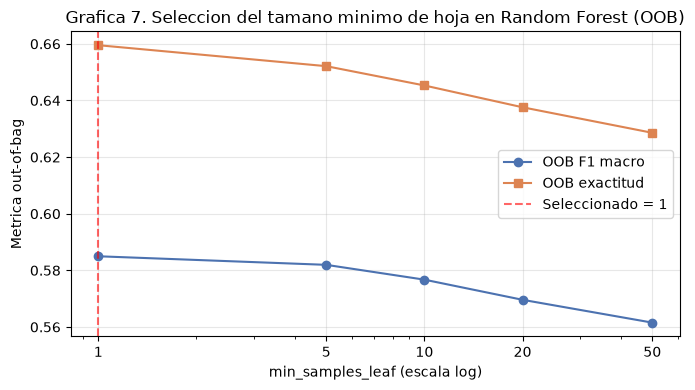

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(oob_rf['min_samples_leaf'], oob_rf['OOB F1 macro'], marker='o', color='#4C72B0', label='OOB F1 macro')
ax.plot(oob_rf['min_samples_leaf'], oob_rf['OOB exactitud'], marker='s', color='#DD8452', label='OOB exactitud')
ax.axvline(msl_opt, color='red', linestyle='--', alpha=0.6, label=f'Seleccionado = {msl_opt}')
ax.set_xscale('log')
ax.set_xticks(hojas)
ax.set_xticklabels(hojas)
ax.set_xlabel('min_samples_leaf (escala log)')
ax.set_ylabel('Metrica out-of-bag')
ax.set_title('Grafica 7. Seleccion del tamano minimo de hoja en Random Forest (OOB)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Aqui podemos ver que la metrica out of bag empieza más alta con hojas de 1 observación (F1 macro de 0.585) y va bajando acorde que las hojas se hacen más grandes, hasta 0.562 con 50. Lo mismo pasa con la exactitud OOB. Entonces vamos a escoger:

min_samples_leaf = 1

Esto es distinto a lo que salió en el proyecto de [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md) (donde se eligió 5). La diferencia entre 1 y 5 aquí es muy chica (0.585 contra 0.582, menos de 0.005), así que en la práctica los dos valores son casi equivalentes y el resultado puede cambiar ligeramente según la versión de sklearn con la que se corra. Se respeta lo que diga el OOB, porque es el criterio que se definió de antemano y se calcula solo con entrenamiento.

In [25]:
def entrenar_rf(X, y):
    return RFC(n_estimators=300, max_features='sqrt', min_samples_leaf=msl_opt,
               class_weight='balanced', n_jobs=-1, random_state=67).fit(X, y)

validacion_cruzada('Random Forest', entrenar_rf, X_train_a)

=== Random Forest ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.6572             0.5581                0.5958            0.5734                  0.9335      1.4682
2        0.6559             0.5574                0.6016            0.5747                  0.9324      1.5066
3        0.6572             0.5574                0.5975            0.5735                  0.9352      1.5531
4        0.6603             0.5622                0.6013            0.5780                  0.9328      1.8918
5        0.6580             0.5590                0.6049            0.5769                  0.9334      1.5753

F1 macro (validacion): 0.5753 +/- 0.0021
Exactitud (validacion): 0.6577 +/- 0.0016
F1 macro (entrenamiento): 0.9335


- El Random Forest obtiene un **F1 macro de 0.575** en validación y una **exactitud de 65.8%**, la exactitud más alta de todos los modelos hasta ahora, y con una mejora clara sobre el árbol podado (+0.035 en F1 macro y +6 puntos de exactitud).
- Es por mucho el modelo **más estable**: su F1 solo varía entre 0.573 y 0.578 entre folds (desviación estándar de 0.002, más de cuatro veces menor que la del árbol). Esto es exactamente lo que se espera del bagging: promediar 300 árboles reduce la varianza de un árbol individual.
- Pero hay una **brecha enorme entre entrenamiento (0.933) y validación (0.575)**. Con hojas de 1 observación, cada árbol memoriza casi todo su set de entrenamiento. Esto no le pega en validación (al promediar los árboles los errores se cancelan), pero sí quiere decir que el desempeño en entrenamiento de un Random Forest no sirve para evaluarlo.
- Un detalle: el F1 macro OOB (0.585) salió un poco más optimista que la validación cruzada (0.575).

## Boosting

### Selección de hiperparámetros

Se usa `GradientBoostingClassifier` de `sklearn.ensemble` con:

- `max_depth=3`: árboles pequeños (8 hojas como máximo). En boosting la idea es usar "weak learners" que aprendan poco a poco; árboles de profundidad 3 permiten capturar interacciones entre variables (por ejemplo, ingreso *y* tipo de localidad) sin ser demasiado complejos.
- `learning_rate=0.1`: cuánto aporta cada árbol nuevo. Es el valor por default y un buen equilibrio entre aprender rápido y no sobreajustar.
- `subsample=0.8`: cada árbol se entrena con un 80% de los datos elegido al azar (*stochastic gradient boosting*), lo que reduce la varianza y acelera el entrenamiento.
- `n_estimators=500` con **early stopping** (`validation_fraction=0.1` y `n_iter_no_change=10`): se aparta el 10% del entrenamiento como validación, y el modelo deja de agregar árboles cuando la pérdida en validación no mejora durante 10 iteraciones. Así el número de árboles lo decide el propio entrenamiento y no hay que adivinarlo.
- Pesos balanceados: `GradientBoostingClassifier` no tiene el parámetro `class_weight`, así que se le pasan pesos por observación (`sample_weight`) calculados con `compute_sample_weight('balanced')`, que es exactamente lo mismo.

Se eligió Gradient Boosting sobre AdaBoost porque es la versión más usada en la práctica y porque permite early stopping de forma directa.

Ahora vamos a ver como esta aprendiendo el modelo, entonces vamos a graficar como cambian la pérdida y el F1 conforme van agregando los arboles. Para esto primero se entrena una vez apartando un 10% del **entrenamiento** como validación (no se usa el set de prueba).

Arboles usados tras early stopping: 315


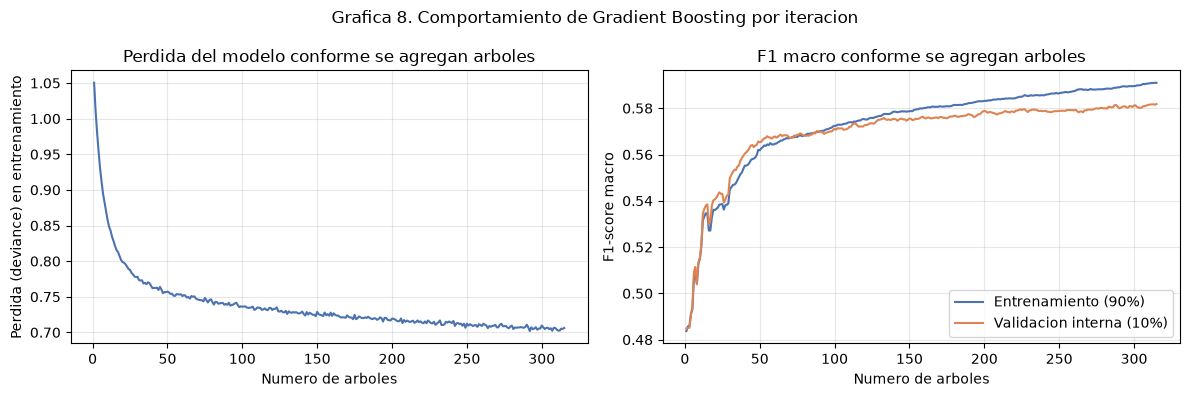

F1 macro final - entrenamiento: 0.5910   validacion interna: 0.5818


In [26]:
#Codigo hecho con claude
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.utils.class_weight import compute_sample_weight

def crear_gb():
    return GBC(n_estimators=500,          # maximo de arboles (el early stopping decide cuantos usar)
               learning_rate=0.1,         # tamano de paso de cada arbol
               max_depth=3,               # arboles pequenos ("weak learners")
               subsample=0.8,             # cada arbol ve 80% de los datos (stochastic gradient boosting)
               validation_fraction=0.1,   # 10% de entrenamiento se aparta para decidir cuando parar
               n_iter_no_change=10,       # paciencia: 10 arboles sin mejora -> se detiene
               random_state=67)

# Validacion interna: 90% / 10% del ENTRENAMIENTO
Xg_tr, Xg_va, yg_tr, yg_va = train_test_split(X_train_a, y_train, test_size=0.1,
                                              random_state=67, stratify=y_train)
gb_demo = crear_gb()
gb_demo.fit(Xg_tr, yg_tr, sample_weight=compute_sample_weight('balanced', yg_tr))
print("Arboles usados tras early stopping:", gb_demo.n_estimators_)

f1_etapas_tr = [f1_score(yg_tr, p, average='macro') for p in gb_demo.staged_predict(Xg_tr)]
f1_etapas_va = [f1_score(yg_va, p, average='macro') for p in gb_demo.staged_predict(Xg_va)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, gb_demo.n_estimators_ + 1), gb_demo.train_score_, color='#4C72B0')
axes[0].set_xlabel('Numero de arboles')
axes[0].set_ylabel('Perdida (deviance) en entrenamiento')
axes[0].set_title('Perdida del modelo conforme se agregan arboles')
axes[0].grid(alpha=0.3)

axes[1].plot(np.arange(1, gb_demo.n_estimators_ + 1), f1_etapas_tr, color='#4C72B0', label='Entrenamiento (90%)')
axes[1].plot(np.arange(1, gb_demo.n_estimators_ + 1), f1_etapas_va, color='#DD8452', label='Validacion interna (10%)')
axes[1].set_xlabel('Numero de arboles')
axes[1].set_ylabel('F1-score macro')
axes[1].set_title('F1 macro conforme se agregan arboles')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.suptitle('Grafica 8. Comportamiento de Gradient Boosting por iteracion')
plt.tight_layout()
plt.show()
print(f"F1 macro final - entrenamiento: {f1_etapas_tr[-1]:.4f}   validacion interna: {f1_etapas_va[-1]:.4f}")

- El early stopping paro el boosting en **315 árboles** (de un máximo de 500): a partir de ahí, 10 árboles seguidos no mejoraron la pérdida en su validación interna.
- En la gráfica de la izquierda la pérdida en entrenamiento baja rápido en los primeros ~50 árboles y después sigue bajando cada vez más despacio: cada árbol nuevo aporta menos.
- En la de la derecha, el F1 macro sube rápido al principio y después se aplana alrededor de 0.58. Las curvas de entrenamiento y validación interna van prácticamente encimadas hasta unos 100 árboles; a partir de ahí la de entrenamiento se separa poco a poco, pero al final la diferencia es de solo ~0.01 (0.591 contra 0.582), así que no hay un sobreajuste preocupante. Simplemente llega un punto en el que cada árbol nuevo aporta muy poco, y ahí es donde el early stopping corta, antes de que la separación entre entrenamiento y validación se haga grande.

In [27]:
def entrenar_gb(X, y):
    return crear_gb().fit(X, y, sample_weight=compute_sample_weight('balanced', y))

validacion_cruzada('Gradient Boosting', entrenar_gb, X_train_a)

=== Gradient Boosting ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.6474             0.5589                0.6786            0.5802                  0.5912     19.8493
2        0.6403             0.5525                0.6709            0.5735                  0.5842     11.9745
3        0.6505             0.5600                0.6768            0.5834                  0.5959     20.8731
4        0.6480             0.5569                0.6743            0.5786                  0.5873     13.5323
5        0.6511             0.5604                0.6769            0.5820                  0.5890     15.0436

F1 macro (validacion): 0.5795 +/- 0.0038
Exactitud (validacion): 0.6474 +/- 0.0043
F1 macro (entrenamiento): 0.5895


- El Gradient Boosting obtiene un **F1 macro de 0.580**, el **más alto de todos los modelos**, con una exactitud de 64.7% (un punto menos que el Random Forest).
- Tiene la **sensibilidad macro más alta** de todos (0.676): es el que mejor detecta a las personas de las clases minoritarias.
- Su brecha entre entrenamiento (0.590) y validación (0.580) es de solo 0.010, así que **casi no sobreajusta**, gracias al early stopping y a que usa árboles chiquitos.
- Es estable (desviación estándar de 0.004), aunque un poco menos que el Random Forest. El costo es el tiempo: es secuencial (no se puede paralelizar como el Random Forest), así que tarda unas 10 veces más por fold (~16 segundos contra ~1.6 del Random Forest).

## Support Vector Machine

### Selección de hiperparámetros

La SVM tiene un problema práctico importante: el tiempo de entrenamiento de `SVC` crece aproximadamente con el cuadrado (o más) del número de observaciones, y la predicción depende del número de vectores de soporte. Con las 96,344 observaciones de entrenamiento, entrenar (y más aún hacer validación cruzada) tomaría muchísimo tiempo. Por eso se trabaja con **submuestras estratificadas del set de entrenamiento**:

1. Para elegir el kernel y $C$ se usa una submuestra de 8,000 observaciones y validación cruzada estratificada de 3 folds.
2. En la validación cruzada de comparación, en cada fold la SVM se entrena con una submuestra estratificada de **20,000 observaciones** del fold de entrenamiento, pero se evalúa con el fold de validación **completo**, igual que los demás modelos. Así la comparación sigue siendo justa en cuanto a con qué se evalúa, aunque la SVM entrene con menos datos (esto se toma en cuenta en las conclusiones).

Los hiperparámetros que se prueban son:

- **Kernel:** lineal (una frontera plana, equivalente a un *support vector classifier*) contra RBF (radial, que permite fronteras no lineales).
- **$C$:** qué tanto se castigan las violaciones del margen (0.1, 1 y 10).
- `gamma='scale'` para el kernel RBF (el valor por default de sklearn, que se ajusta según la varianza de los datos).
- `class_weight='balanced'` en todos los casos, por la misma razón que en los demás modelos.

In [28]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Submuestra pequena y estratificada del set de ENTRENAMIENTO para elegir kernel y C
X_cv, _, y_cv, _ = train_test_split(X_train_s, y_train, train_size=8000,
                                    random_state=67, stratify=y_train)

param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale']},
]
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=67)
t0 = time.time()
busqueda = GridSearchCV(SVC(class_weight='balanced'), param_grid,
                        scoring='f1_macro', cv=skf3, n_jobs=-1)
busqueda.fit(X_cv, y_cv)
print(f"Tiempo de la busqueda: {time.time() - t0:.1f} s\n")

res_svm = pd.DataFrame(busqueda.cv_results_)[['param_kernel', 'param_C', 'mean_test_score', 'std_test_score']]
res_svm.columns = ['Kernel', 'C', 'F1 macro (CV)', 'Desv. est.']
print(res_svm.round(4).to_string(index=False))
print("\nMejor combinacion:", busqueda.best_params_)

Tiempo de la busqueda: 4.9 s

Kernel    C  F1 macro (CV)  Desv. est.
linear  0.1         0.4664      0.0052
linear  1.0         0.4664      0.0052
   rbf  0.1         0.5107      0.0038
   rbf  1.0         0.5229      0.0109
   rbf 10.0         0.5237      0.0093

Mejor combinacion: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


- El **kernel lineal** se queda en un F1 macro de 0.466 (sin importar $C$), muy parecido a la regresión logística, lo cual tiene sentido porque los dos son clasificadores lineales.
- El **kernel RBF** es claramente mejor (0.511 a 0.524): otra vez se ve que la frontera entre sectores **no es lineal**.
- Entre los valores de $C$ con kernel RBF, la diferencia entre 1 y 10 es mínima (0.523 contra 0.524, mucho menor que la desviación estándar entre folds), pero se elige $C=10$ porque es el mejor en promedio.

In [29]:
def entrenar_svm(X, y):
    return make_pipeline(StandardScaler(),
                         SVC(**busqueda.best_params_, class_weight='balanced')).fit(X, y)

validacion_cruzada('SVM', entrenar_svm, X_train_e, n_sub=20000)

=== SVM ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.5903             0.5152                0.6380            0.5271                  0.5374      8.0510
2        0.5807             0.5056                0.6282            0.5164                  0.5406      7.9066
3        0.5843             0.5114                0.6322            0.5246                  0.5419      7.6790
4        0.5908             0.5147                0.6313            0.5291                  0.5542      7.9071
5        0.5951             0.5141                0.6350            0.5296                  0.5450      7.7803

F1 macro (validacion): 0.5254 +/- 0.0054
Exactitud (validacion): 0.5883 +/- 0.0057
F1 macro (entrenamiento): 0.5438


- La SVM obtiene un **F1 macro de 0.525** y una exactitud de 58.8%: **queda por debajo del árbol podado** (0.541), aunque es muchísimo más compleja.
- Cada fold tardó unos 8 segundos en entrenar **usando solo 20,000 observaciones** (una cuarta parte del fold); con el fold completo tardaría muchísimo más, porque el costo crece con el cuadrado del número de datos. Esto también la pone en desventaja frente a los demás modelos, que sí usan las ~77 mil observaciones de cada fold, y hay que tenerlo en cuenta al interpretar el resultado.
- La brecha entre entrenamiento (0.544) y validación (0.525) es pequeña (0.019), así que no hay sobreajuste importante; la SVM simplemente no encuentra una mejor frontera con estas variables.

## Red neuronal

### Selección de hiperparámetros

Se construye desde cero una red neuronal *feedforward* sencilla con `Sequential` de Keras (TensorFlow). No se necesita `Flatten` porque la entrada ya es un vector de 6 variables.

- **Capa de entrada:** 6 neuronas (las 6 variables estandarizadas, con `log_ingocup`).
- **2 capas ocultas `Dense`** con 32 y 16 neuronas y activación **ReLU**. Con solo 6 variables de entrada no tiene sentido una red muy grande; una red chica ya tiene suficiente flexibilidad para capturar relaciones no lineales, y menos parámetros implica menos riesgo de sobreajuste.
- **Capa de salida:** 3 neuronas (una por sector) con activación **softmax**.
- **Optimizador Adam** con *learning rate* de **0.0005**. Es la mitad del valor por default (0.001), así que la red da pasos más pequeños en cada actualización: aprende un poco más lento, pero de forma más estable.
- **Pérdida `sparse_categorical_crossentropy`**, porque las etiquetas son enteros (0, 1, 2).
- **Batch size de 32**: los pesos se actualizan cada 32 observaciones. Con batches pequeños cada época tarda más, pero el ruido en el gradiente ayuda a regularizar el modelo.
- **Hasta 100 épocas con early stopping** (`patience=10`, `restore_best_weights=True`): si la pérdida en validación no mejora en 10 épocas, se detiene y se regresa a los pesos de la mejor época.
- **Validación:** **20% del set de entrenamiento** (`validation_split=0.2`), para que el set de prueba no influya en ninguna decisión del entrenamiento.
- **Pesos por clase balanceados** (`class_weight`), igual que en el resto de los modelos.

A diferencia del proyecto de [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md), aquí se usan **exactamente los mismos hiperparámetros** (learning rate de 0.0005 y batch de 32) tanto en el entrenamiento de ejemplo como en la validación cruzada, para que lo que se reporta en la comparación sea el mismo modelo que se describe.

In [30]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

def crear_red():
    red = Sequential([
        Input(shape=(len(vars_escala),)),     # capa de entrada: 6 variables escaladas
        Dense(32, activation='relu'),         # capa oculta 1
        Dense(16, activation='relu'),         # capa oculta 2
        Dense(3, activation='softmax')        # capa de salida: 1 neurona por clase
    ])
    red.compile(optimizer=Adam(learning_rate=0.0005),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
    return red

def pesos_balanceados(y_nn):
    # Pesos por clase equivalentes a class_weight='balanced' de sklearn
    return dict(enumerate(compute_class_weight('balanced', classes=np.unique(y_nn), y=y_nn)))

tf.keras.utils.set_random_seed(67)   # para que los resultados sean reproducibles
red_demo = crear_red()
red_demo.summary()
print("Pesos por clase:", {clases[k]: round(float(v), 3) for k, v in pesos_balanceados(y_train.values - 1).items()})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803 (3.14 KB)

 Trainable params: 803 (3.14 KB)

 Non-trainable params: 0 (0.00 B)

Pesos por clase: {'Primario': 4.436, 'Secundario': 1.241, 'Terciario': 0.508}


La red tiene en total **803 parámetros entrenables** (224 en la primera capa oculta, 528 en la segunda y 51 en la de salida), y los pesos por clase hacen que cada error en una persona del sector primario cuente 4.4 veces, uno del secundario 1.2 veces y uno del terciario solo 0.5 veces, para compensar el desbalance. Aun siendo una red "chica", tiene bastantes más parámetros que la regresión logística, lo que le da más flexibilidad para capturar relaciones no lineales entre las variables.

### Entrenamiento de ejemplo

Se entrena la red una vez con todo el set de entrenamiento (con el 20% de validación interna) para ver cómo se comportan sus curvas de aprendizaje.

In [31]:
# Keras necesita las clases como 0, 1, 2 (en vez de 1, 2, 3)
y_train_nn = y_train.values - 1

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
t0 = time.time()
historial = red_demo.fit(X_train_s.values, y_train_nn,
                         epochs=100,
                         batch_size=32,
                         validation_split=0.2,       # 20% del ENTRENAMIENTO como validacion (no se usa prueba)
                         class_weight=pesos_balanceados(y_train_nn),
                         callbacks=[early_stopping],
                         verbose=0)
t_nn = time.time() - t0
print(f"Tiempo de entrenamiento: {t_nn:.1f} s")
print("Epocas ejecutadas:", len(historial.history['loss']))
print("Mejor epoca (menor val_loss):", int(np.argmin(historial.history['val_loss'])) + 1)
# F1 macro en el 20% de validacion interna (Keras toma el ultimo 20% de las filas)
corte = int(len(X_train_s) * 0.8)
p_tr_nn = red_demo.predict(X_train_s.values[:corte], verbose=0, batch_size=2048).argmax(axis=1)
p_va_nn = red_demo.predict(X_train_s.values[corte:], verbose=0, batch_size=2048).argmax(axis=1)
print(f"F1 macro - entrenamiento (80%): {f1_score(y_train_nn[:corte], p_tr_nn, average='macro'):.4f}   "
      f"validacion interna (20%): {f1_score(y_train_nn[corte:], p_va_nn, average='macro'):.4f}")


Tiempo de entrenamiento: 55.2 s
Epocas ejecutadas: 88
Mejor epoca (menor val_loss): 78
F1 macro - entrenamiento (80%): 0.5573   validacion interna (20%): 0.5430


Se tardo menos de un minuto (53 segundos) en 88 epocas, y la mejor epoca fue la 78, que es con la que se queda la red gracias a `restore_best_weights`. En la validación interna saca un F1 macro de 0.543 contra 0.557 en el 80% con el que entrena. Ahora vamos a graficar para ver mejor los resultados

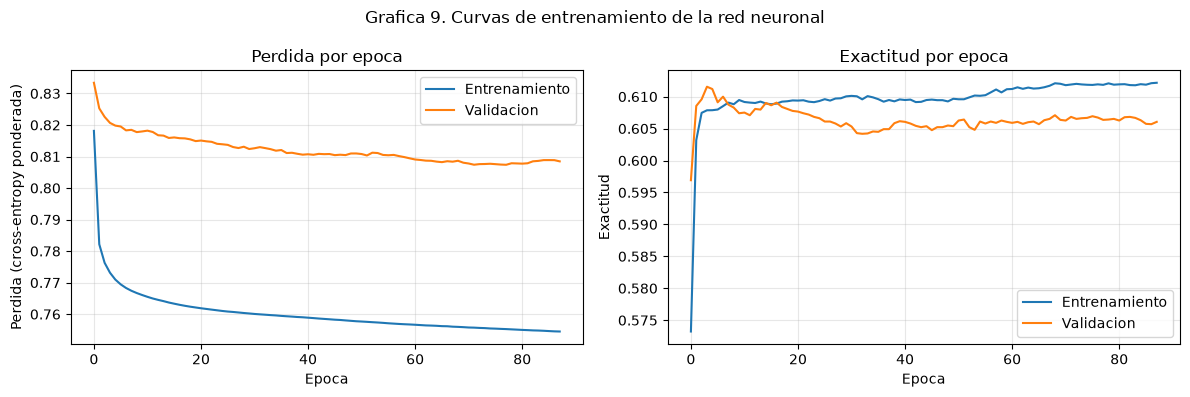

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(historial.history['loss'], label='Entrenamiento')
axes[0].plot(historial.history['val_loss'], label='Validacion')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Perdida (cross-entropy ponderada)')
axes[0].set_title('Perdida por epoca')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(historial.history['accuracy'], label='Entrenamiento')
axes[1].plot(historial.history['val_accuracy'], label='Validacion')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Exactitud')
axes[1].set_title('Exactitud por epoca')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.suptitle('Grafica 9. Curvas de entrenamiento de la red neuronal')
plt.tight_layout()
plt.show()

Podemos ver que las dos curvas de exactitud suben muy rápido en las primeras 3 o 4 epocas. Despues la de validación baja un poquito (de 0.611 a como 0.605) y se queda casi plana, mientras que la de entrenamiento se queda alrededor de 0.61 y despues de la epoca 60 sube muy poquito. Que la exactitud baje no es malo: la red no está optimizando la exactitud sino la pérdida con pesos por clase, entonces conforme aprende a detectar más primario y secundario sacrifica algunos aciertos de terciario (lo mismo que pasa con todos los modelos balanceados). La separación entre entrenamiento y validación es de menos de 1 punto, entonces no hay sobreajuste importante.

En la pérdida, la de validación siempre queda arriba de la de entrenamiento (0.81 contra 0.76), pero esto no quiere decir que haya sobreajuste: Keras solo le aplica los pesos por clase a la pérdida de entrenamiento y no a la de validación, entonces las dos no se calculan igual. Lo que sí se ve es que la pérdida de validación sigue bajando poco a poco hasta la epoca 78 y ya despues no mejora, por eso el early stopping corta en la 88.

In [33]:
#Codigo hecho con claude
def entrenar_red(X, y):
    tf.keras.utils.set_random_seed(67)
    esc = StandardScaler().fit(X)              # el escalador se ajusta dentro del fold
    red = crear_red()
    y_nn = y.values - 1
    red.fit(esc.transform(X), y_nn, epochs=100, batch_size=32, validation_split=0.2,
            class_weight=pesos_balanceados(y_nn), verbose=0,
            callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    return (esc, red)

def predecir_red(modelo, X):
    esc, red = modelo
    return red.predict(esc.transform(X), verbose=0, batch_size=2048).argmax(axis=1) + 1   # se regresa a 1, 2, 3

validacion_cruzada('Red neuronal', entrenar_red, X_train_e, predecir=predecir_red)

=== Red neuronal ===
      Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  F1 macro entrenamiento  Tiempo (s)
Fold                                                                                                          
1        0.6139             0.5310                0.6490            0.5503                  0.5506     28.3148
2        0.5976             0.5212                0.6412            0.5362                  0.5442     31.1900
3        0.6172             0.5372                0.6420            0.5593                  0.5612     33.2368
4        0.5990             0.5221                0.6384            0.5364                  0.5395     11.7991
5        0.6008             0.5202                0.6414            0.5306                  0.5372     42.8523

F1 macro (validacion): 0.5426 +/- 0.0118
Exactitud (validacion): 0.6057 +/- 0.0091
F1 macro (entrenamiento): 0.5465


Ahora en la validación cruzada, con los mismos 5 folds que los demás modelos, la red neuronal saca un **F1 macro de 0.543** y una exactitud de 60.6%.

- Entre entrenamiento (0.547) y validación (0.543) no hay mucha diferencia (0.004), entonces no hay sobreajuste, gracias al early stopping.
- A base de los demás, le gana a la SVM por 0.017 de F1 macro y por casi 2 puntos de exactitud, y queda prácticamente empatada con el árbol podado (0.543 contra 0.541; le gana en 4 de los 5 folds pero por muy poco). Pero pierde contra el Random Forest (0.575) y contra el Boosting (0.580) por más de 0.03 de F1 macro.
- Es el modelo **menos estable** de todos: su F1 va de 0.531 a 0.559 entre folds (desviación estándar de 0.012, más que el árbol). Esto tiene sentido porque el resultado de una red depende de la inicialización aleatoria de sus pesos y de en qué época se detiene el early stopping (en un fold tardó 12 segundos y en otro 43).
- Comparado con el proyecto de [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md) (F1 macro de 0.531 en validación cruzada, con una submuestra de 20,000 y otros hiperparámetros), aquí sale un poco mejor, porque ahora cada red entrena con ~77 mil observaciones y con los mismos hiperparámetros que el entrenamiento de ejemplo.

En general este modelo le gana a la SVM y empata con el árbol, pero pierde contra el boosting y el random forest.

# Comparación de modelos (validación cruzada)

Vamos a juntarlo en una tabla para ver las diferencias. Ya con los 7 modelos (más la referencia) evaluados en los mismos 5 folds, se juntan los resultados en una tabla. Todos los números de esta sección vienen de la validación cruzada sobre el set de entrenamiento; el set de prueba sigue sin usarse.

In [34]:
#Tabla hecha con claude
from IPython.display import display

orden_modelos = ['Referencia (siempre terciario)', 'Regresion logistica', 'LDA', 'Arbol de decision',
                 'Random Forest', 'Gradient Boosting', 'SVM', 'Red neuronal']
orden_modelos = [m for m in orden_modelos if m in cv_folds]   # la red solo aparece si ya se corrio
metricas_tabla = ['Exactitud', 'Precision (macro)', 'Sensibilidad (macro)', 'F1-score (macro)']

tabla_cv = pd.DataFrame({m: cv_folds[m].mean() for m in orden_modelos}).T
tabla_cv['Desv. est. F1'] = [cv_folds[m]['F1-score (macro)'].std() for m in orden_modelos]
tabla_cv['Brecha F1 (entren. - valid.)'] = tabla_cv['F1 macro entrenamiento'] - tabla_cv['F1-score (macro)']
tabla_cv = tabla_cv[metricas_tabla + ['Desv. est. F1', 'F1 macro entrenamiento',
                                      'Brecha F1 (entren. - valid.)', 'Tiempo (s)']]

modelos_reales = orden_modelos[1:]
tabla_bonita = (tabla_cv.style
    .format({c: '{:.3f}' for c in tabla_cv.columns if c != 'Tiempo (s)'} | {'Tiempo (s)': '{:.1f} s'})
    .highlight_max(subset=pd.IndexSlice[modelos_reales, metricas_tabla], props='background-color: #C6EFCE; font-weight: bold')
    .background_gradient(subset=['F1-score (macro)'], cmap='Blues')
    .set_caption('Tabla 3. Promedio de 5 folds de validacion cruzada (set de entrenamiento)')
    .set_table_styles([
        {'selector': 'caption', 'props': 'font-size: 14px; font-weight: bold; padding-bottom: 8px;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #4C72B0; color: white; padding: 6px 10px;'},
        {'selector': 'td', 'props': 'text-align: center; padding: 6px 10px;'},
    ]))
display(tabla_bonita)
print(tabla_cv.round(4).to_string())

,Exactitud,Precision (macro),Sensibilidad (macro),F1-score (macro),Desv. est. F1,F1 macro entrenamiento,Brecha F1 (entren. - valid.),Tiempo (s)
Referencia (siempre terciario),0.656,0.219,0.333,0.264,0.000,0.264,-0.000,0.0 s
Regresion logistica,0.555,0.484,0.609,0.490,0.003,0.490,0.000,0.1 s
LDA,0.495,0.449,0.524,0.436,0.005,0.437,0.000,0.0 s
Arbol de decision,0.596,0.523,0.639,0.541,0.009,0.542,0.002,1.0 s
Random Forest,0.658,0.559,0.600,0.575,0.002,0.933,0.358,1.6 s
Gradient Boosting,0.647,0.558,0.675,0.580,0.004,0.590,0.010,16.3 s
SVM,0.588,0.512,0.633,0.525,0.005,0.544,0.018,7.9 s
Red neuronal,0.606,0.526,0.642,0.543,0.012,0.547,0.004,29.5 s


                                Exactitud  Precision (macro)  Sensibilidad (macro)  F1-score (macro)  Desv. est. F1  F1 macro entrenamiento  Brecha F1 (entren. - valid.)  Tiempo (s)
Referencia (siempre terciario)     0.6562             0.2187                0.3333            0.2641         0.0000                  0.2641                       -0.0000      0.0011
Regresion logistica                0.5545             0.4837                0.6091            0.4901         0.0025                  0.4903                        0.0001      0.0585
LDA                                0.4949             0.4494                0.5241            0.4362         0.0046                  0.4366                        0.0004      0.0177
Arbol de decision                  0.5960             0.5235                0.6394            0.5405         0.0090                  0.5423                        0.0017      0.9669
Random Forest                      0.6577             0.5588                0.6002        

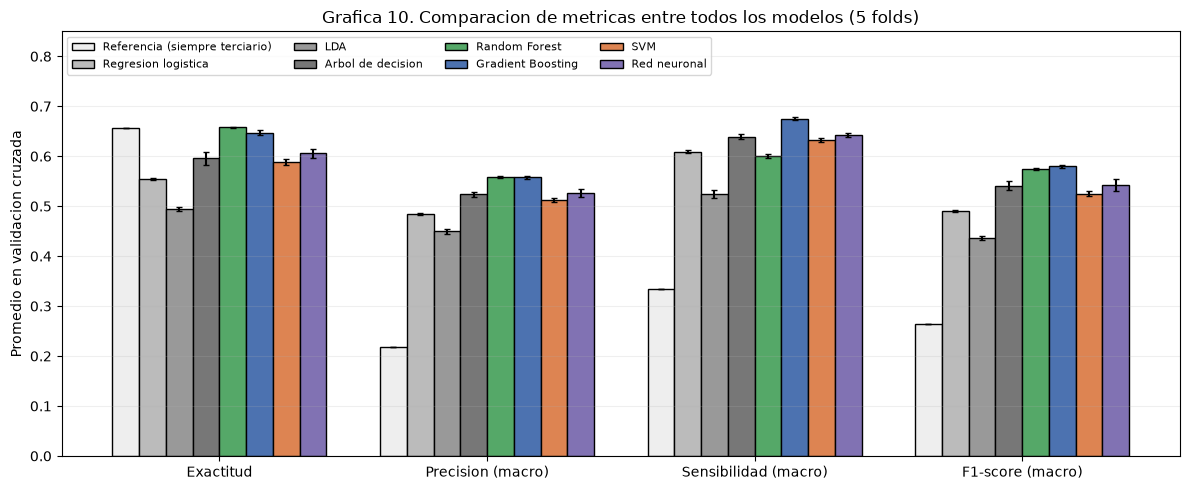

In [35]:
#Codigo hecho con claude
colores_m = {'Referencia (siempre terciario)': '#EEEEEE', 'Regresion logistica': '#BBBBBB', 'LDA': '#999999',
             'Arbol de decision': '#777777', 'Random Forest': '#55A868', 'Gradient Boosting': '#4C72B0',
             'SVM': '#DD8452', 'Red neuronal': '#8172B3'}

fig, ax = plt.subplots(figsize=(12, 5))
ancho = 0.8 / len(orden_modelos)
x = np.arange(len(metricas_tabla))
for i, m in enumerate(orden_modelos):
    vals = tabla_cv.loc[m, metricas_tabla].astype(float).values
    errs = [cv_folds[m][met].std() for met in metricas_tabla]
    ax.bar(x + i * ancho - 0.4 + ancho / 2, vals, width=ancho, yerr=errs, capsize=2, label=m,
           color=colores_m[m], edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(metricas_tabla)
ax.set_ylim(0, 0.85)
ax.set_ylabel('Promedio en validacion cruzada')
ax.set_title('Grafica 10. Comparacion de metricas entre todos los modelos (5 folds)')
ax.legend(ncol=4, fontsize=8, loc='upper left')
ax.grid(alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

**Qué modelo tuvo mejor desempeño:**

- El **Gradient Boosting** es el mejor en F1 macro (0.580) y en sensibilidad macro (0.676), y queda casi empatado con el Random Forest en precisión macro (0.558 contra 0.559).
- El **Random Forest** queda en segundo lugar en F1 macro (0.575) y es el mejor en exactitud (65.8%) y en precisión macro (0.559).
- La **red neuronal** queda en tercer lugar (0.543), casi empatada con el **árbol podado** (0.541), y los dos por arriba de la **SVM** (0.525).
- Los modelos lineales (regresión logística 0.490 y LDA 0.436) quedan claramente abajo, aunque muy por encima de la referencia (0.264).
- Ningún modelo supera la exactitud de la referencia (65.6%), y eso está bien: todos sacrifican aciertos en terciario para detectar a primario y secundario, que es justo lo que se busca.

## Detalle por clase

El F1 macro esconde que cada modelo tiene un "estilo" distinto de equivocarse. Con las predicciones **fuera de fold** (cada persona del entrenamiento fue predicha por el modelo del fold en el que quedó como validación, o sea por un modelo que no la vio), se calcula la sensibilidad y la precisión de cada sector para cada modelo.

In [36]:
modelos_reales = [m for m in orden_modelos if m != 'Referencia (siempre terciario)']
recall_clase = pd.DataFrame({m: recall_score(y_train, oof[m], average=None) for m in modelos_reales},
                            index=['Recall ' + c for c in clases]).T
precision_clase = pd.DataFrame({m: precision_score(y_train, oof[m], average=None) for m in modelos_reales},
                               index=['Precision ' + c for c in clases]).T
print(pd.concat([recall_clase, precision_clase], axis=1).round(3).to_string())

                     Recall Primario  Recall Secundario  Recall Terciario  Precision Primario  Precision Secundario  Precision Terciario
Regresion logistica            0.839              0.406             0.583               0.264                 0.378                0.809
LDA                            0.582              0.513             0.478               0.179                 0.390                0.780
Arbol de decision              0.786              0.532             0.601               0.320                 0.421                0.827
Random Forest                  0.565              0.505             0.731               0.424                 0.458                0.794
Gradient Boosting              0.808              0.549             0.669               0.332                 0.495                0.846
SVM                            0.811              0.481             0.607               0.292                 0.415                0.828
Red neuronal                   0.792     

Aquí se ve muy bien que los dos mejores modelos se equivocan de forma distinta:

- **Primario:** el Gradient Boosting detecta al **80.8%** de las personas del campo, contra solo **56.5%** del Random Forest. A cambio, el Random Forest es más preciso cuando dice "primario" (0.424 contra 0.332). Con hojas de 1 observación, los pesos balanceados casi no tienen efecto en el Random Forest, y por eso se comporta más como un modelo sin balancear: le cuesta predecir la clase más chica.
- **Secundario** es la clase más difícil para todos: ningún modelo pasa de 55% de sensibilidad ni de 0.50 de precisión. El Gradient Boosting es el que mejor lo detecta (54.9%) y también el más preciso (0.495).
- **Terciario:** el Random Forest es el que mejor lo detecta (73.1%), por eso tiene la mejor exactitud (terciario es la clase más grande); el Gradient Boosting se queda en 66.9% pero con la mejor precisión (0.846).
- La **red neuronal** se comporta muy parecido al Boosting pero un poco peor en todo: detecta al 79.2% de primario, 51.2% de secundario y 62.2% de terciario, con precisiones más bajas en primario (0.307) y secundario (0.437).

En resumen, el Gradient Boosting es el más **equilibrado** entre las 3 clases, y el Random Forest favorece a la clase mayoritaria.

## ¿Las diferencias son sustanciales o marginales?

Para responder esto no basta con ver el promedio: hay que ver cuánto **varía** el desempeño de cada modelo entre folds. Si la diferencia entre dos modelos es mucho más grande que la variación entre folds, la diferencia es real; si es del mismo tamaño, es marginal. Como todos los modelos se evaluaron con **los mismos 5 folds**, también se puede comparar fold por fold: si un modelo le gana a otro en los 5 folds, la ventaja es consistente.

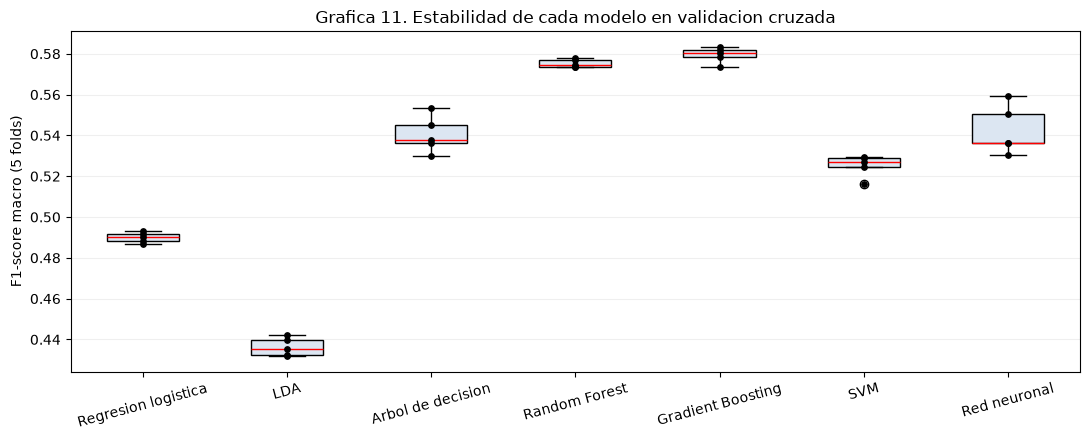

                     F1 promedio  Desv. est.  Dif. vs arbol  Folds que le gana al arbol  Dif. vs Random Forest  Folds que le gana al RF
Regresion logistica       0.4901      0.0025        -0.0504                           0                -0.0852                        0
LDA                       0.4362      0.0046        -0.1043                           0                -0.1391                        0
Arbol de decision         0.5405      0.0090         0.0000                           0                -0.0348                        0
Random Forest             0.5753      0.0021         0.0348                           5                 0.0000                        0
Gradient Boosting         0.5795      0.0038         0.0390                           5                 0.0042                        4
SVM                       0.5254      0.0054        -0.0152                           0                -0.0500                        0
Red neuronal              0.5426      0.0118    

In [37]:
#Codigo hecho con claude
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([cv_folds[m]['F1-score (macro)'] for m in modelos_reales], tick_labels=modelos_reales, patch_artist=True,
           boxprops=dict(facecolor='#DCE6F2'), medianprops=dict(color='red'))
for i, m in enumerate(modelos_reales, start=1):
    ax.scatter(np.full(5, i), cv_folds[m]['F1-score (macro)'], color='black', s=15, zorder=3)
ax.set_ylabel('F1-score macro (5 folds)')
ax.set_title('Grafica 11. Estabilidad de cada modelo en validacion cruzada')
plt.xticks(rotation=15)
ax.grid(alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

# Comparacion fold por fold contra el Random Forest y contra el arbol
f1_folds = pd.DataFrame({m: cv_folds[m]['F1-score (macro)'] for m in modelos_reales})
comp = pd.DataFrame({
    'F1 promedio': f1_folds.mean(),
    'Desv. est.': f1_folds.std(),
    'Dif. vs arbol': f1_folds.mean() - f1_folds['Arbol de decision'].mean(),
    'Folds que le gana al arbol': (f1_folds.gt(f1_folds['Arbol de decision'], axis=0)).sum(),
    'Dif. vs Random Forest': f1_folds.mean() - f1_folds['Random Forest'].mean(),
    'Folds que le gana al RF': (f1_folds.gt(f1_folds['Random Forest'], axis=0)).sum(),
})
print(comp.round(4).to_string())

- La desviación estándar entre folds es pequeña en todos los modelos (entre 0.002 y 0.012), así que los resultados son **estables**.
- **Gradient Boosting vs árbol podado:** 0.580 contra 0.541, una mejora de 0.039, más de 4 veces la desviación estándar del árbol, y le gana en los 5 folds. **La mejora es sustancial.**
- **Random Forest vs árbol podado:** 0.575 contra 0.541 (+0.035), también le gana en los 5 folds. **También es sustancial.**
- **Gradient Boosting vs Random Forest:** 0.580 contra 0.575. La diferencia (0.004) es pequeña: el Boosting le gana al Random Forest en 4 de los 5 folds, y en el que pierde (el fold 2) es por apenas 0.001. Es una ventaja **marginal** en F1 macro; donde sí hay una diferencia grande es en la forma de equivocarse (ver detalle por clase).
- **Red neuronal vs árbol podado:** 0.543 contra 0.541, una diferencia de solo 0.002, mucho más chica que la desviación estándar de cualquiera de los dos (0.012 y 0.009). Aunque le gana en 4 de los 5 folds, **la diferencia es marginal**: la red no mejora de verdad al árbol sencillo, a pesar de ser mucho más compleja.
- **SVM vs árbol podado:** 0.525 contra 0.541, la SVM pierde en todos los folds. **La SVM no aporta una mejora**, y eso que es mucho más costosa.
- **Regresión logística y LDA** quedan 0.05 y 0.10 abajo del árbol, diferencias claramente sustanciales.

## Complejidad del modelo, sobreajuste y costo

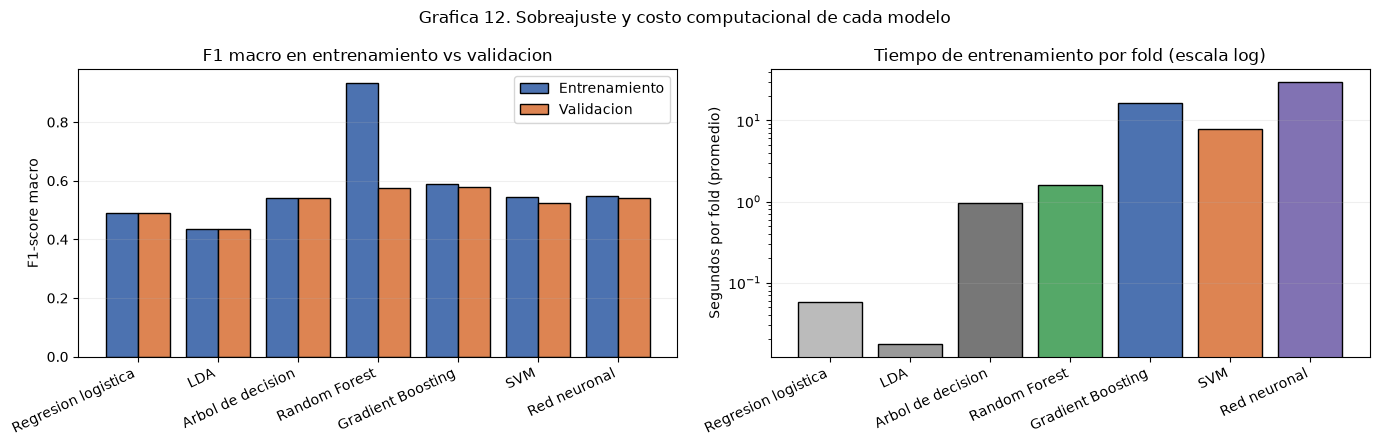

                     F1 macro entrenamiento  F1-score (macro)  Brecha F1 (entren. - valid.)  Tiempo (s)
Regresion logistica                  0.4903            0.4901                        0.0001      0.0585
LDA                                  0.4366            0.4362                        0.0004      0.0177
Arbol de decision                    0.5423            0.5405                        0.0017      0.9669
Random Forest                        0.9335            0.5753                        0.3582      1.5990
Gradient Boosting                    0.5895            0.5795                        0.0100     16.2546
SVM                                  0.5438            0.5254                        0.0185      7.8648
Red neuronal                         0.5465            0.5426                        0.0040     29.4786


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(modelos_reales))
axes[0].bar(x - 0.2, tabla_cv.loc[modelos_reales, 'F1 macro entrenamiento'], width=0.4, color='#4C72B0', edgecolor='black', label='Entrenamiento')
axes[0].bar(x + 0.2, tabla_cv.loc[modelos_reales, 'F1-score (macro)'], width=0.4, color='#DD8452', edgecolor='black', label='Validacion')
axes[0].set_xticks(x)
axes[0].set_xticklabels(modelos_reales, rotation=25, ha='right')
axes[0].set_ylabel('F1-score macro')
axes[0].set_title('F1 macro en entrenamiento vs validacion')
axes[0].legend()
axes[0].grid(alpha=0.2, axis='y')

axes[1].bar(x, tabla_cv.loc[modelos_reales, 'Tiempo (s)'], color=[colores_m[m] for m in modelos_reales], edgecolor='black')
axes[1].set_xticks(x)
axes[1].set_xticklabels(modelos_reales, rotation=25, ha='right')
axes[1].set_ylabel('Segundos por fold (promedio)')
axes[1].set_yscale('log')
axes[1].set_title('Tiempo de entrenamiento por fold (escala log)')
axes[1].grid(alpha=0.2, axis='y')
plt.suptitle('Grafica 12. Sobreajuste y costo computacional de cada modelo')
plt.tight_layout()
plt.show()
print(tabla_cv.loc[modelos_reales, ['F1 macro entrenamiento', 'F1-score (macro)', 'Brecha F1 (entren. - valid.)', 'Tiempo (s)']].round(4).to_string())

Juntando todo:

| Modelo | Complejidad | F1 macro CV | Mejora vs árbol | Tiempo por fold | Brecha entren.–valid. |
|---|---|---|---|---|---|
| Regresión logística | Baja (lineal) | 0.490 | −0.050 | < 1 s | 0.000 |
| LDA | Baja (lineal) | 0.436 | −0.104 | < 1 s | 0.000 |
| Árbol podado | Baja–media (~39 hojas) | 0.541 | — | ~1 s | 0.002 |
| Random Forest | Alta (300 árboles profundos) | 0.575 | +0.035 | ~2 s | 0.358 |
| Gradient Boosting | Alta (~300 árboles secuenciales) | **0.580** | **+0.039** | ~16 s | 0.010 |
| SVM (RBF) | Alta (miles de vectores de soporte) | 0.525 | −0.015 | ~8 s (con solo 20,000 datos) | 0.019 |
| Red neuronal | Alta (803 parámetros, 2 capas ocultas) | 0.543 | +0.002 | ~29 s | 0.004 |

(Los tiempos pueden variar dependiendo de la computadora; lo importante es la diferencia relativa entre modelos.)

**Relación entre complejidad y desempeño:**

- El salto más grande en desempeño se dio al pasar de modelos **lineales** a modelos **no lineales** (de 0.49 de la logística a 0.54 del árbol): la frontera entre sectores simplemente no es lineal.
- Pasar de **un árbol a muchos árboles** (Random Forest y Boosting) dio otra mejora clara, aunque más chica (+0.035 a +0.039).
- Pero **más complejidad no siempre significa mejor desempeño**: la SVM, que es de las más costosas (tarda 8 segundos por fold entrenando con solo una cuarta parte de los datos), quedó abajo del árbol. Su complejidad está en un lugar (fronteras suaves en un espacio de dimensión infinita) que no le ayuda a este problema, donde las variables binarias y los cortes por umbral (como los que hacen los árboles) capturan mejor la estructura de los datos.
- Algo parecido pasa con la **red neuronal**: queda prácticamente igual que el árbol (0.543 contra 0.541, una diferencia marginal), casi no sobreajusta (brecha de 0.004, gracias al early stopping), pero es el modelo que más tarda en entrenar por fold y el menos estable entre folds. Con solo 6 variables tabulares, su flexibilidad extra no se traduce en una mejora real.
- **Sobreajuste:** el único con una brecha grande es el Random Forest (0.36). No le afecta en validación, pero indica que cada árbol memoriza sus datos. El Gradient Boosting, en cambio, logra el mejor F1 con una brecha de solo 0.010.
- Las mejoras son **moderadas** en términos absolutos: ningún modelo llega a 0.60 de F1 macro. Esto indica que el límite no está tanto en el modelo sino en la **información disponible**: con solo 6 variables sociodemográficas, secundario y terciario se parecen demasiado y ningún modelo, por complejo que sea, puede separarlos bien.

## Ventajas y limitaciones de cada modelo

### Interpretabilidad

De más a menos interpretable:

1. **Regresión logística y LDA:** sus coeficientes y funciones discriminantes se pueden leer directo, pero son los que peor predicen porque sus fronteras son lineales (y LDA ni siquiera puede usar `ur01` y `sex01`).
2. **Árbol podado:** se puede leer regla por regla, pero es de los menos estables.
3. **Random Forest y Gradient Boosting:** no se pueden leer los cientos de árboles, pero sí dan importancia de variables.
4. **SVM y red neuronal:** son cajas negras, no dan ninguna medida directa de qué variables usan. Y encima no predijeron mejor que el árbol, entonces pierden en los dos lados.

### ¿Cuándo usar cada uno?

- **Regresión logística:** como modelo base, o si lo que interesa es interpretar el efecto de cada variable (odds ratios) más que predecir.
- **LDA:** no la usaría aquí, porque no puede usar las variables binarias que son las que más separan a los sectores, y sus supuestos se cumplen solo a medias.
- **Árbol de decisión:** si tuviera que explicarle el modelo a alguien no técnico, aunque pierda un poco de desempeño.
- **Random Forest:** si lo más importante fuera la exactitud total y la estabilidad. Es el más estable, entrena en segundos y da importancia de variables, pero se le escapa casi la mitad del sector primario.
- **Gradient Boosting:** si lo más importante es no dejar fuera a las personas del campo o de la industria (por ejemplo, para un programa de apoyo), porque tiene la sensibilidad más alta en primario y secundario y el mejor F1 macro.
- **SVM:** no la usaría aquí. Hay que entrenarla con submuestras porque no escala bien a 96 mil observaciones, y no le gana ni al árbol. Tendría más sentido en problemas con menos observaciones y más variables continuas.
- **Red neuronal:** tampoco la usaría aquí. Es la que más tarda por fold, no se puede interpretar, es la menos estable y queda igual que un árbol que entrena en un segundo. Una red neuronal tiene sentido con muchos datos y patrones complejos, como imágenes (MNIST), no con 6 variables tabulares.

# Selección del modelo final

Con base en la comparación, el modelo final es el **Gradient Boosting**. La decisión se justifica así:

**Evidencia cuantitativa (validación cruzada, sin tocar el set de prueba):**

- Tiene el **mejor F1 macro** (0.580), que es la métrica principal definida desde el inicio, por arriba de todos los demás modelos: le gana al árbol, a la SVM y a la red neuronal en los 5 folds, y al Random Forest en 4 de 5.
- Tiene la **mejor sensibilidad macro** (0.676) y el detalle por clase más equilibrado: detecta al 81% del sector primario y al 55% del secundario, las dos clases más difíciles, sin descuidar al terciario (67%, con la precisión más alta, 0.85).
- Es **estable** (desviación estándar de 0.004 entre folds) y casi **no sobreajusta** (brecha de 0.010 entre entrenamiento y validación).

**Evidencia cualitativa:**

- **Coherencia con el problema:** la motivación social del proyecto se enfoca justo en las clases minoritarias (sobre todo el sector primario, la población rural con menores ingresos). Un modelo que se le escapa casi la mitad del sector primario, como el Random Forest (56% de sensibilidad), sería poco útil para ese propósito, aunque tenga mejor exactitud.
- **Interpretabilidad:** no se puede leer árbol por árbol como el árbol podado, pero sí da la importancia de cada variable, y sus árboles son chiquitos (profundidad 3). Es más interpretable que la SVM o la red neuronal, que son cajas negras.
- **Costo:** tarda más en entrenar que el Random Forest (unos 16 segundos por fold contra menos de 2), pero es un costo totalmente aceptable, y predecir es casi instantáneo.


No escogi el random forest, si es el más estable y el de mejor exactitud, y seria una opción razonable si lo unico que fuera de imporatncia fuera acertar el mayor numero de personas en total. Pero su ventaja Pero su ventaja en exactitud viene de predecir más seguido la clase mayoritaria, y en F1 macro (la métrica que se definió como principal) queda abajo en 4 de los 5 folds. Además, tiene una brecha de sobreajuste muy grande. Y no nos queremos enfocar solo en el más grandeñ. No se escogio el random forest porque es inestable y tiene 0.04 de F1 score menos. Y finalmente no se escogio la red neuronal ya que queda 0.037 abajo del boosting en F1 mscro score, y es el que más tarda en entrenar

Es importante notar que la ventaja del Boosting sobre el Random Forest en F1 macro es pequeña (0.004); lo que inclina la balanza es que le gane en 4 de los 5 folds y que se equivoque de una forma más alineada con el objetivo del proyecto.

# Evaluación del desempeño del modelo final en el conjunto de prueba

Se reentrena el Gradient Boosting con **todo** el set de entrenamiento (96,344 personas, con los mismos hiperparámetros y pesos balanceados; el early stopping vuelve a decidir el número de árboles usando el 10% interno del entrenamiento) y se evalúa **una sola vez** en el set de prueba (24,086 personas que no se usaron en ninguna decisión anterior).

In [39]:
t0 = time.time()
modelo_final = crear_gb()
modelo_final.fit(X_train_a, y_train, sample_weight=compute_sample_weight('balanced', y_train))
print(f"Tiempo de entrenamiento: {time.time() - t0:.1f} s")
print("Arboles usados tras early stopping:", modelo_final.n_estimators_)

pred_test = modelo_final.predict(X_test_a)
metricas_test = {
    'Exactitud': accuracy_score(y_test, pred_test),
    'Precision (macro)': precision_score(y_test, pred_test, average='macro'),
    'Sensibilidad (macro)': recall_score(y_test, pred_test, average='macro'),
    'F1-score (macro)': f1_score(y_test, pred_test, average='macro'),
}
comparacion = pd.DataFrame({
    'Validacion cruzada (promedio)': tabla_cv.loc['Gradient Boosting', metricas_tabla],
    'Validacion cruzada (desv. est.)': cv_folds['Gradient Boosting'][metricas_tabla].std(),
    'Conjunto de prueba': pd.Series(metricas_test),
    'Referencia en prueba (siempre terciario)': pd.Series({
        'Exactitud': accuracy_score(y_test, np.full(len(y_test), 3)),
        'Precision (macro)': precision_score(y_test, np.full(len(y_test), 3), average='macro', zero_division=0),
        'Sensibilidad (macro)': recall_score(y_test, np.full(len(y_test), 3), average='macro'),
        'F1-score (macro)': f1_score(y_test, np.full(len(y_test), 3), average='macro'),
    })
})
print()
print(comparacion.round(4).to_string())
print()
print(classification_report(y_test, pred_test, target_names=clases, digits=3))

Tiempo de entrenamiento: 17.5 s
Arboles usados tras early stopping: 249

                      Validacion cruzada (promedio)  Validacion cruzada (desv. est.)  Conjunto de prueba  Referencia en prueba (siempre terciario)
Exactitud                                    0.6474                           0.0043              0.6414                                    0.6562
Precision (macro)                            0.5577                           0.0032              0.5523                                    0.2187
Sensibilidad (macro)                         0.6755                           0.0030              0.6682                                    0.3333
F1-score (macro)                             0.5795                           0.0038              0.5734                                    0.2641

              precision    recall  f1-score   support

    Primario      0.326     0.796     0.463      1810
  Secundario      0.487     0.546     0.515      6471
   Terciario      0.843     

El early stopping volvió a decidir el tamaño del modelo y se quedó con **249 árboles**. En el conjunto de prueba el Gradient Boosting obtiene:

- **F1 macro de 0.573**, contra 0.580 ± 0.004 que se había estimado en validación cruzada. La diferencia (0.006) es del tamaño de la variación normal entre folds, es decir, **el modelo se comportó con datos nuevos prácticamente como se esperaba**. Esto confirma que la validación cruzada fue una buena estimación y que no hubo sobreajuste en la selección.
- **Exactitud de 64.1%** (64.7% en validación cruzada).
- Contra la referencia de "siempre terciario", el F1 macro es más del doble (0.573 contra 0.264). La exactitud es un poco menor que la de la referencia (64.1% contra 65.6%), pero la referencia no detecta a nadie del campo ni de la industria, y el modelo sí.

**¿Qué quiere decir esto en palabras?** Si al modelo le llegan los datos de personas nuevas (su edad, escolaridad, horas, ingreso, sexo y si viven en zona rural), se puede esperar que:

- **Sector primario:** de cada 10 personas que de verdad trabajan en el campo, **identifica a 8** (sensibilidad de 0.796). Pero cuando dice "esta persona es del campo", **solo acierta 1 de cada 3 veces** (precisión de 0.326): marca como "primario" a mucha gente de zonas rurales con perfil parecido que en realidad trabaja en la industria o en servicios. Esto es consecuencia directa de haber pedido que no ignore a la clase más chica (pesos balanceados): se prefirió detectar a casi todos aunque haya falsos positivos.
- **Sector secundario:** identifica a poco más de la mitad (55%), y cuando dice "industria" acierta la mitad de las veces (0.487). Es la clase más difícil.
- **Sector terciario:** identifica a 2 de cada 3 (66%), y cuando dice "servicios" acierta **84 de cada 100 veces**, la precisión más alta de las 3 clases.

### ¿Qué tan seguro es ese número?

El F1 macro de prueba es un solo número calculado con 24,086 personas; si se hubiera tomado otra muestra de personas, saldría un poco distinto. Para dar un rango, se hace un *bootstrap* sobre el set de prueba: se toman 1,000 remuestreos con reemplazo de las predicciones ya hechas (el modelo no se vuelve a entrenar), se calcula el F1 macro y la exactitud en cada uno, y se reporta el intervalo que contiene al 95% de ellos.

In [40]:
#Codigo hecho con claude
rng = np.random.default_rng(67)
yt, pt = y_test.values, pred_test
boot_f1, boot_acc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot_f1.append(f1_score(yt[idx], pt[idx], average='macro'))
    boot_acc.append(accuracy_score(yt[idx], pt[idx]))
ic_f1 = np.percentile(boot_f1, [2.5, 97.5])
ic_acc = np.percentile(boot_acc, [2.5, 97.5])
print(f"F1 macro en prueba: {metricas_test['F1-score (macro)']:.4f}   IC 95%: [{ic_f1[0]:.4f}, {ic_f1[1]:.4f}]")
print(f"Exactitud en prueba: {metricas_test['Exactitud']:.4f}   IC 95%: [{ic_acc[0]:.4f}, {ic_acc[1]:.4f}]")

F1 macro en prueba: 0.5734   IC 95%: [0.5657, 0.5807]
Exactitud en prueba: 0.6414   IC 95%: [0.6350, 0.6480]


Con una muestra de este tamaño el resultado es bastante preciso: el F1 macro en prueba está entre **0.566 y 0.581** con 95% de confianza, y la exactitud entre **63.5% y 64.8%**. El valor de validación cruzada (0.580) cae dentro de ese intervalo, otra confirmación de que lo que se estimó con el entrenamiento se sostiene con datos que el modelo no vio. Para datos nuevos de la misma población (personas ocupadas de la ENOE), lo razonable es esperar un F1 macro de alrededor de 0.57 y una exactitud de alrededor de 64%.

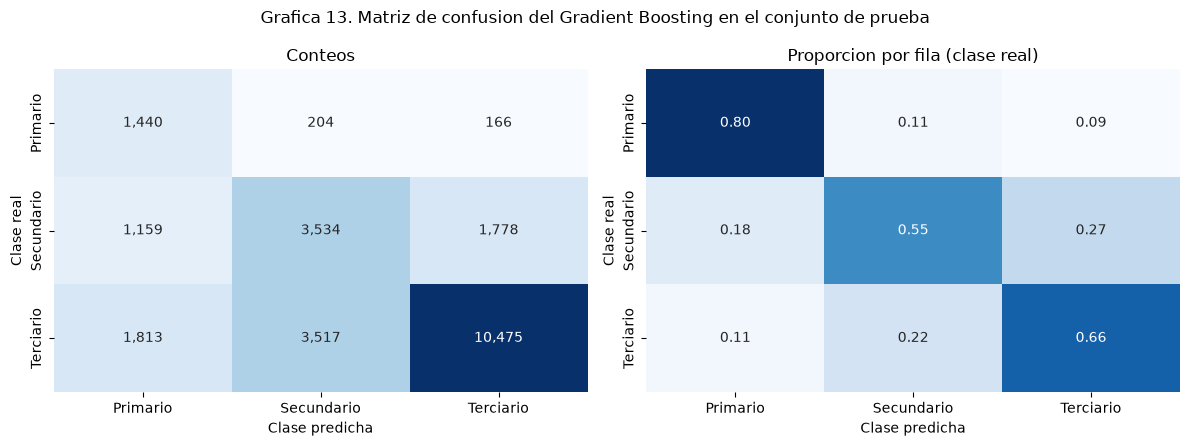

            Primario  Secundario  Terciario
Primario        1440         204        166
Secundario      1159        3534       1778
Terciario       1813        3517      10475


In [41]:
#Codigo hecho con claude
def graficar_cm(y_real, y_pred, titulo):
    """Matriz de confusion en conteos y normalizada por fila (sensibilidad por clase)."""
    cm = confusion_matrix(y_real, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=clases, yticklabels=clases, ax=axes[0])
    axes[0].set_title('Conteos')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False,
                xticklabels=clases, yticklabels=clases, ax=axes[1])
    axes[1].set_title('Proporcion por fila (clase real)')
    for ax in axes:
        ax.set_xlabel('Clase predicha')
        ax.set_ylabel('Clase real')
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    return cm

cm_test = graficar_cm(y_test, pred_test, 'Grafica 13. Matriz de confusion del Gradient Boosting en el conjunto de prueba')
print(pd.DataFrame(cm_test, index=clases, columns=clases))

En la matriz de confusión, las filas son el sector real y las columnas el sector que predijo el modelo; la diagonal son los aciertos. En la gráfica de la derecha cada fila suma 1, así que la diagonal es la sensibilidad de cada sector:

- **Primario (80%):** de las 1,810 personas del campo en prueba, 1,440 se clasificaron bien. Solo 204 se fueron a secundario y 166 a terciario.
- **Secundario (55%):** de 6,471, se clasificaron bien 3,534; **1,778 (27%) se confunden con terciario** y 1,159 (18%) con primario.
- **Terciario (66%):** de 15,805, se clasificaron bien 10,475; **3,517 (22%) se confunden con secundario** y 1,813 (11%) con primario.

La confusión más grande es entre secundario y terciario, en las dos direcciones, porque son los sectores con perfiles más parecidos en escolaridad, ingreso y horas trabajadas (como ya se veía en la Gráfica 3). El primario es, por mucho, el más fácil de distinguir: casi todos sus errores son personas de otros sectores que se "parecen" al primario (rurales, hombres, con poca escolaridad e ingreso bajo). Entonces este modelo aunque se confunde entre secundario y terciario, son clases muy parecidas, entonces comoquiera lo pondria como un modelo solido.

## Importancia de variables del modelo final

Para entender qué está usando el modelo para decidir, se revisan dos medidas de importancia:

- **Importancia por impureza:** cuánto reduce cada variable la pérdida en promedio en todos los árboles del boosting. Es rápida, pero tiende a favorecer a las variables continuas con muchos valores posibles.
- **Importancia por permutación:** se revuelven al azar los valores de una variable en el set de prueba y se mide cuánto baja el F1 macro. Si al revolverla el modelo empeora mucho, es que esa variable de verdad le sirve. Como el modelo ya está elegido y entrenado, esto no cambia nada del modelo; solo ayuda a interpretarlo.

           Importancia por impureza  Caida de F1 macro al permutar
ur01                         0.3936                         0.0676
sex01                        0.1604                         0.0544
hrsocup                      0.1214                         0.0519
ingocup                      0.1936                         0.0494
anios_esc                    0.1112                         0.0294
eda                          0.0198                         0.0047


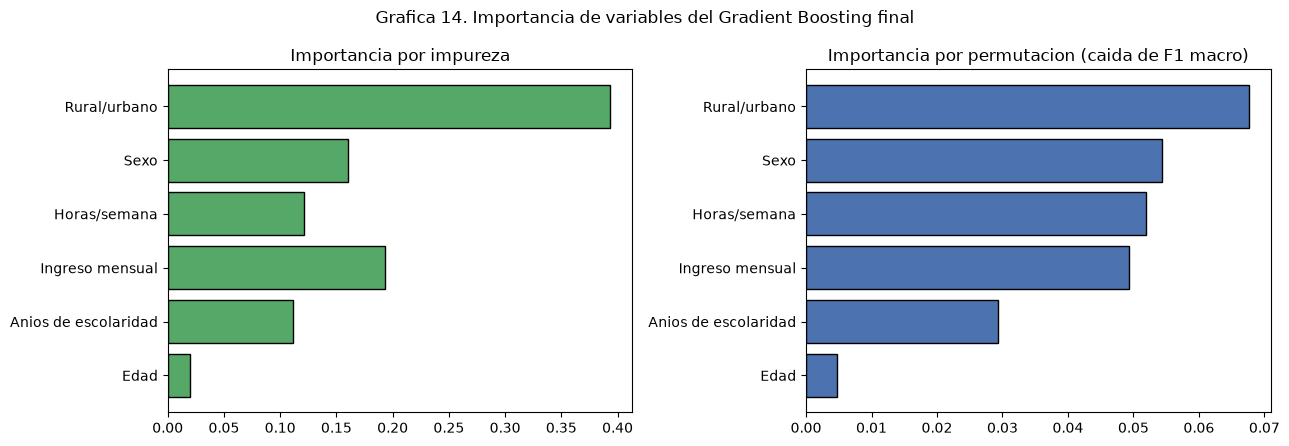

In [42]:
#Codigo hecho con claude
from sklearn.inspection import permutation_importance

imp_gini = pd.Series(modelo_final.feature_importances_, index=vars_arbol)
perm = permutation_importance(modelo_final, X_test_a, y_test, scoring='f1_macro',
                              n_repeats=5, random_state=67, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=vars_arbol)
tabla_imp = pd.DataFrame({'Importancia por impureza': imp_gini,
                          'Caida de F1 macro al permutar': imp_perm}).sort_values('Caida de F1 macro al permutar', ascending=False)
print(tabla_imp.round(4))

nombres_bonitos = {'eda': 'Edad', 'anios_esc': 'Anios de escolaridad', 'hrsocup': 'Horas/semana',
                   'ingocup': 'Ingreso mensual', 'sex01': 'Sexo', 'ur01': 'Rural/urbano'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = tabla_imp.iloc[::-1]
axes[0].barh([nombres_bonitos[v] for v in t.index], t['Importancia por impureza'], color='#55A868', edgecolor='black')
axes[0].set_title('Importancia por impureza')
axes[1].barh([nombres_bonitos[v] for v in t.index], t['Caida de F1 macro al permutar'], color='#4C72B0', edgecolor='black')
axes[1].set_title('Importancia por permutacion (caida de F1 macro)')
plt.suptitle('Grafica 14. Importancia de variables del Gradient Boosting final')
plt.tight_layout()
plt.show()

Las dos medidas coinciden en lo principal:

- **`ur01` (rural/urbano) es la variable más importante** en las dos medidas: concentra el 39% de la importancia por impureza, y si se revuelve al azar el F1 macro cae 0.068, más que con cualquier otra variable.
- Le siguen **`sex01`, `hrsocup` e `ingocup`**, con caídas de F1 de 0.049 a 0.054 al permutarlas. Por impureza el ingreso sale como segunda (0.194), pero la permutación lo pone en un nivel parecido al de sexo y horas; esto es el sesgo de la importancia por impureza a favor de las variables continuas con muchos valores, por eso conviene ver las dos.
- **`anios_esc`** aporta menos de lo que se esperaba por la exploración (caída de 0.029), probablemente porque parte de su información ya la traen el ingreso y el tipo de localidad (están correlacionadas).
- **`eda` casi no sirve** (caída de 0.005): la edad prácticamente no distingue sectores, como ya se veía en la Gráfica 3.

Es decir, para el modelo **dónde vive una persona, su sexo, cuánto trabaja y cuánto gana** son lo que más ayuda a saber en qué sector trabaja.

## Ejemplos de cómo usaría el modelo una persona nueva

Para traducir el modelo a algo concreto, se calculan las probabilidades que le da el Gradient Boosting a algunos perfiles inventados (no son personas de la base).

In [43]:
perfiles = pd.DataFrame([
    {'Perfil': 'Hombre rural, 45 anios, 6 anios de escuela, 48 h, $5,000',      'eda': 45, 'anios_esc': 6,  'hrsocup': 48, 'ingocup': 5000,  'sex01': 0, 'ur01': 1},
    {'Perfil': 'Hombre urbano, 30 anios, 9 anios de escuela, 48 h, $10,000',    'eda': 30, 'anios_esc': 9,  'hrsocup': 48, 'ingocup': 10000, 'sex01': 0, 'ur01': 0},
    {'Perfil': 'Mujer urbana, 35 anios, 16 anios de escuela, 40 h, $15,000',    'eda': 35, 'anios_esc': 16, 'hrsocup': 40, 'ingocup': 15000, 'sex01': 1, 'ur01': 0},
    {'Perfil': 'Mujer rural, 50 anios, 6 anios de escuela, 30 h, $4,000',       'eda': 50, 'anios_esc': 6,  'hrsocup': 30, 'ingocup': 4000,  'sex01': 1, 'ur01': 1},
]).set_index('Perfil')
probas = pd.DataFrame(modelo_final.predict_proba(perfiles[vars_arbol]), index=perfiles.index,
                      columns=['P(Primario)', 'P(Secundario)', 'P(Terciario)'])
probas['Prediccion'] = [clases[i] for i in probas.values.argmax(axis=1)]
print(probas.round(3).to_string())

                                                            P(Primario)  P(Secundario)  P(Terciario) Prediccion
Perfil                                                                                                         
Hombre rural, 45 anios, 6 anios de escuela, 48 h, $5,000          0.911          0.055         0.034   Primario
Hombre urbano, 30 anios, 9 anios de escuela, 48 h, $10,000        0.084          0.411         0.504  Terciario
Mujer urbana, 35 anios, 16 anios de escuela, 40 h, $15,000        0.011          0.230         0.759  Terciario
Mujer rural, 50 anios, 6 anios de escuela, 30 h, $4,000           0.368          0.228         0.404  Terciario


- El **hombre rural** de 45 años con primaria y 5,000 pesos al mes tiene un **91% de probabilidad** de trabajar en el campo: es el perfil "típico" del sector primario y el modelo lo reconoce con mucha seguridad.
- La **mujer urbana** con licenciatura y 15,000 pesos tiene un 76% de probabilidad de trabajar en servicios.
- El **hombre urbano** con secundaria que trabaja 48 horas por 10,000 pesos queda casi empatado entre terciario (50%) y secundario (41%). Este es justo el perfil que el modelo no puede separar: con estas variables, un obrero de fábrica y un empleado de comercio se ven casi iguales.
- La **mujer rural** con primaria y 4,000 pesos queda repartida entre terciario (40%) y primario (37%), lo que refleja que en el campo las mujeres trabajan con frecuencia en comercio y servicios y no solo en actividades agropecuarias.

Esto ayuda a entender el modelo: **cuando una persona tiene un perfil claro, el modelo está muy seguro; en los perfiles "intermedios", las probabilidades salen repartidas**, y es ahí donde se concentran los errores. Pero aqui se ve que hay un resultado decente

Al haber comparado todos los resultados, esto es un modelo solido que en general no se puede mejorar más sin otros datos externos

# Conclusión y reflexión final

Qué se aprendió sobre la problemática?

- **El sector primario tiene un perfil muy marcado y muy ligado a la desigualdad territorial.** El 93% de las personas que trabajan en el campo viven en localidades rurales, tienen en promedio 7 años de escuela (contra 11 en servicios) y una mediana de ingreso de 6,450 pesos al mes (contra 9,460 y 10,750 en servicios e industria). Ese perfil es tan claro que el modelo identifica al 80% de las personas del campo solo con 6 variables. Esto confirma lo que se planteó al inicio: **el lugar donde vive una persona y la escuela a la que tuvo acceso están fuertemente asociados con el tipo de trabajo que tiene**, y con eso, con su ingreso.
- **El sexo pesa mucho en el sector:** el 80% de las mujeres ocupadas trabaja en servicios, y solo el 12.5% de quienes trabajan en el campo son mujeres. Para el modelo, el sexo es la segunda variable más importante.
- **La industria y los servicios no se pueden distinguir bien con el perfil sociodemográfico.** Sus trabajadores tienen escolaridad, ingreso, horas y edad muy parecidos, y ningún modelo, por complejo que sea, logró separarlos bien. Esto también es un hallazgo: la diferencia entre trabajar en una fábrica o en un comercio no depende tanto del perfil de la persona, sino de otros factores (la región, la oferta de empleo local, el tipo de ocupación) que no están en estas variables.

Mejor modelo y que queda más:

El **Gradient Boosting** fue el mejor modelo: tuvo el mejor F1 macro en validación cruzada (0.580, por arriba de todos los demás modelos y ganándole al Random Forest en 4 de los 5 folds), la mejor sensibilidad macro y el comportamiento más equilibrado entre las 3 clases, casi sin sobreajuste. En el conjunto de prueba independiente obtuvo un **F1 macro de 0.573 (IC 95%: 0.566 a 0.581) y una exactitud de 64.1%**, prácticamente lo que se había estimado, lo que da confianza en que se va a comportar igual con datos nuevos.

En cuanto a la relación entre complejidad y desempeño, el aprendizaje principal es que **lo que funcionó no fue la complejidad en sí, sino el tipo de complejidad**: pasar de modelos lineales a árboles dio el salto más grande, y combinar muchos árboles (Random Forest y Boosting) dio otra mejora real. En cambio, la SVM, que es de los modelos más costosos, quedó por debajo de un simple árbol podado, y la red neuronal, que es la que más tarda en entrenar, quedó prácticamente igual que el árbol. Con pocas variables, la mayoría de la información en variables binarias (rural/urbano y sexo) y en cortes de ingreso y escolaridad, los modelos basados en árboles son los que mejor le entienden a estos datos. El Random Forest sería una alternativa razonable si importara más la exactitud total que detectar a las clases chicas, y el árbol podado si hubiera que explicarle el modelo regla por regla a alguien no técnico.

Limitaciones del estudio

- **Pocas variables:** solo se usaron 6 variables sociodemográficas. Esto fue una decisión para responder la pregunta del proyecto (¿el perfil de la persona determina su sector?), pero limita el desempeño: ningún modelo pasa de 0.60 de F1 macro.
- **Un solo trimestre:** los datos son del primer trimestre de 2026. El trabajo agrícola es estacional, así que la proporción del sector primario (y quizás su perfil) puede cambiar en otros trimestres.
- **Diseño de la encuesta:** no se usaron los factores de expansión de la ENOE, así que los porcentajes describen a la muestra y no exactamente a toda la población ocupada de México. Además, las personas de un mismo hogar o de una misma zona pueden parecerse entre sí, y la partición aleatoria no lo toma en cuenta.
- **Población acotada:** solo incluye a personas ocupadas con ingreso positivo y quita a quienes reportaron 0 horas, así que las conclusiones no aplican a personas sin ingreso o trabajadores no remunerados.
- **SVM con submuestra:** por su costo, la SVM se entrenó con 20,000 observaciones por fold, lo que la pone en desventaja frente a los demás modelos.
- **Red neuronal con una sola arquitectura:** solo se probó una red (2 capas ocultas de 32 y 16 neuronas, learning rate fijo); con otras arquitecturas o con regularización (dropout) el resultado podría cambiar un poco, aunque es poco probable que alcance a los ensambles.
- **Hiperparámetros no optimizados de forma exhaustiva:** se tomaron decisiones razonables (y algunas se eligieron con OOB o validación cruzada), pero no se hizo una búsqueda completa para cada modelo; con más búsqueda el Random Forest y el Boosting podrían mejorar un poco.
- **Uso previo de la partición:** se usó la misma partición de entrenamiento y prueba que en los proyectos [LDA vs. árboles de decisión](../sector-economico-lda-arboles/README.md) y [ensambles, SVM y redes neuronales](../sector-economico-ensambles-svm-redes/README.md), donde ya se habían calculado métricas en prueba. En este proyecto la elección del modelo se hizo solo con validación cruzada, pero vale la pena tenerlo presente.

Mejoras y trabajo futuro

- **Agregar información del lugar y del trabajo:** la entidad federativa (la estructura productiva cambia mucho entre estados), el tamaño de la localidad o el tipo de ocupación (variables que no tengan fuga de datos como `ambito2`). Es lo que más probablemente ayudaría a separar industria de servicios.
- **Usar varios trimestres** de la ENOE para ver si los resultados son estables en el tiempo y si cambian con la temporada agrícola.
- **Incorporar los factores de expansión** para que las conclusiones representen a toda la población ocupada.

### Conclusión

Con solo 6 variables del perfil de una persona se puede predecir su sector económico mucho mejor que al azar, y sobre todo se puede identificar con bastante seguridad a quienes trabajan en el campo, porque su perfil (rural, hombre, con poca escolaridad e ingresos bajos) es muy distinto al del resto. Esto es una señal de que en México **el tipo de trabajo al que una persona tiene acceso sigue muy ligado al lugar donde vive y a la escolaridad que pudo alcanzar**. En cambio, los trabajadores de la industria y los servicios se parecen demasiado como para separarlos con estas variables, y para mejorar de verdad no hace falta un modelo más complejo, sino más información sobre el contexto donde trabaja cada persona.

# Tablero interactivo

Como complemento para un público no técnico, los resultados de este reporte se pueden explorar en un tablero interactivo: https://foamyhomie327.github.io/Inteligencia-Artificial/sector-economico-comparacion-modelos/app/

El tablero no cambia la metodología ni el modelo, solo presenta los resultados: la relación de cada variable con el sector, la comparación de los 7 modelos en validación cruzada, la matriz de confusión de cada uno, el desempeño del modelo final en prueba, y un simulador donde se cambia el perfil de una persona (edad, escolaridad, horas, ingreso, sexo y tipo de localidad) para ver qué sector predice cada modelo y cómo influye cada variable.

# Referencias

- INEGI (2026). *Encuesta Nacional de Ocupación y Empleo (ENOE), primer trimestre de 2026*. Microdatos. Instituto Nacional de Estadística y Geografía. https://www.inegi.org.mx/programas/enoe/15ymas/
- INEGI. *Encuesta Nacional de Ocupación y Empleo. Diccionario de datos, SDEMT225*. https://www.inegi.org.mx/rnm/index.php/catalog/1121/data-dictionary/F42?file_name=SDEMT225
- INEGI. *Conociendo la base de datos de la ENOE*. https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/metodologias/est/702825001357.pdf

- Documentación de TensorFlow/Keras. https://www.tensorflow.org/api_docs/python/tf/keras